# Offline EnKF: forecast skill vs. sensor sampling frequency

**Site:** USGS 07022000, Mississippi River at Thebes, IL

This notebook measures how the rate at which a river-level sensor reports data affects the skill of a forecast that assimilates its measurements. An Ensemble Kalman Filter (EnKF) uses each measurement to correct a noisy ensemble forecast of stream level. The more often the sensor reports, the more corrections the filter makes and the narrower and more accurate the ensemble becomes, so it separates events from non-events better. Skill is scored by the hit rate (HR) and false alarm rate (FAR) of threshold-exceedance alarms. We derive closed-form curves $HR(f)$ and $FAR(f)$ in the sampling frequency $f$, which tell a sampling-rate controller how much forecast skill each extra measurement per hour buys.

The setup is an observing-system simulation experiment: the true stream level is real USGS data, while the sensor measurements and the forecasts are synthetic, generated from that truth. The true error of every forecast is therefore known.

### Pipeline

1. **Load data** (Section 2): hourly solar irradiance and 30-minute USGS stream levels.
2. **Build the truth and the sensor measurements** (Section 6): interpolate the stream levels to a 1-minute series (the truth), add Gaussian sensor noise, and subsample to each frequency under test.
3. **Generate synthetic forecasts** (Sections 3, 4.2 and 6): for every 12-hour window, draw an ensemble of trajectories around the truth whose error grows with lead time.
4. **Run the EnKF** (Sections 4.3, 4.4 and 6): assimilate the noisy measurements window by window and save the analysed ensembles as Parquet files.
5. **Evaluate skill** (Sections 4.5 and 7): score the saved forecasts against the truth, giving HR and FAR for each frequency, trial and alarm threshold.
6. **Fit skill curves** (Section 8): fit $HR(f)$ and $FAR(f)$ to the trial-averaged scores.

### 1. Setup

In [45]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.optimize import minimize, curve_fit
from scipy.interpolate import interp1d
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec
from matplotlib.animation import FuncAnimation
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from tqdm import tqdm
import glob, pickle, datetime, time
from collections import defaultdict
np.set_printoptions(threshold=np.inf, precision=5)

### 2. Input data

**Solar irradiance.** Hourly all-sky surface shortwave irradiance (GHI) from NASA POWER. GHI is the solar energy available to the sensor node.

In [46]:
# Read the GHI Input Data, derived from NASA POWER VIEWER
solar_df = pd.read_csv(r"./data/GHI Data USGS Site.csv", header=9, engine='python', skipfooter=0)
solar_df['datetime'] = pd.to_datetime(solar_df[['YEAR', 'MO', 'DY', 'HR']].astype(str).agg('-'.join, axis=1), format='%Y-%m-%d-%H')
solar_df['MO'] = solar_df['datetime'].dt.month
solar_df['DY'] = solar_df['datetime'].dt.day
solar_df['HR'] = solar_df['datetime'].dt.hour
historical_avg = (solar_df.groupby(['MO', 'DY', 'HR'])['ALLSKY_SFC_SW_DWN'].transform('mean'))
solar_df['Average'] = historical_avg

**Stream level.** USGS instantaneous stream level every 30 minutes for 2021. This series is treated as the true river state.

In [ ]:
# Read the Streamlevels input data, derived from USGS
threat_data_raw = pd.read_csv(r"./data/processed_mississippi_data_interpolated_2021_2022.csv")
threat_data_raw = threat_data_raw.interpolate(method='polynomial', order=5)
threat_data_raw["Unit"] = pd.to_datetime(threat_data_raw["Unit"])

### 3. Forecast error model

Synthetic forecast errors are drawn from a zero-mean Gaussian process over lead time $\tau$ (hours from the start of the window). The covariance is an RBF kernel scaled by a growth function:

$$\Sigma(\tau_i, \tau_j) = \sigma^2 \exp\left(-\frac{(\tau_i - \tau_j)^2}{2\ell^2}\right) g(\tau_i)\, g(\tau_j), \qquad g(\tau) = \alpha\sqrt{\tau}$$

- `kernel` is the RBF term. Its `t` argument is the length scale $\ell$ (hours) and `sigma` is the amplitude $\sigma$.
- `growth_martingale` is $g(\tau)$. It follows the martingale model of forecast evolution (MMFE): forecast error builds up from independent increments, so its variance grows linearly with lead time.

The error SD at lead time $\tau$ is therefore $\sigma\alpha\sqrt{\tau}$. The ensemble forms a smooth fan that widens with lead time.

In [48]:
def kernel(x1, x2, t=1.0, sigma=1):
    """
    RBF Kernel used to model a Gaussian Process
    """
    sqdist = np.subtract.outer(x1, x2)**2
    return sigma**2 * np.exp(-0.5*sqdist / (t**2))

def growth_martingale(t, alpha=0.1):
    """
    A forecast is supposed to grow more uncertain as the lead time increases.
    Variance grows linearly with lead time.
    """
    return alpha * np.sqrt(t + 1e-6)

### 4. Helper functions

In [49]:
def get_observational_data(threat_data_raw, inter_transmission_time):
    df = threat_data_raw.copy()
    df['Unit'] = pd.to_datetime(df['Unit'])
    df = df.set_index('Unit')
    resampled_parts = []
    start = df.index.min()
    for dt_min in tqdm(inter_transmission_time):
        end = start + pd.Timedelta(hours=1)
        df_hour = df.loc[start:end]
        if df_hour.empty:
            print(f"Empty: {df_hour}")
            print(f"End Time: {end}")
        if not df_hour.empty:
            dt_sec = int(round(dt_min * 60))
            df_r = (
                df_hour
                .resample(f'{dt_sec}s', origin=start, closed='left', label='left')
                .mean()
                .interpolate(method='time')
            )
            resampled_parts.append(df_r)
            # mask = (df_r.index >= start) & (df_r.index < end)
            # resampled_parts.append(df_r[mask])
        start = end
    threat_resampled = pd.concat(resampled_parts, ignore_index=False)
    threat_resampled.index = threat_resampled.index.tz_localize(None)
    return threat_resampled

### 4.1 Initial forecast ensemble: `generate_confidence_fans`

Builds the synthetic forecasts the EnKF starts from. A new window opens every `step_hours` and covers `horizon_hours`. In each window, member $n$ of the `n_samples` members is

$$x^{(n)}(\tau) = y_{\text{true}}(\tau) + \epsilon^{(n)}(\tau) + b^{(n)}$$

where $\epsilon^{(n)}$ is drawn from the Section 3 error model and $b^{(n)} \sim \mathcal{N}(\mu_b, \sigma_b^2)$ is a constant per-member bias (zero in this experiment). The members are centred on the truth, so before any assimilation the forecast's only defect is its spread. That spread is what the EnKF narrows.

It also plots the truth with the 95% Confidence Interval of the ensemble.

In [50]:
def generate_confidence_fans(observed_df, sigma, bias, n_samples=1000, horizon_hours=4, step_hours=1, t=1, alpha=0.2, seed=None, viz=False):
    """
    Generate ensemble trajectories over a fixed forecasting horizon
    using observation timestamps, suitable for EnKF updates.
    Forecast uncertainty increases linearly with time
    """
    if viz:
        fontsize=19
        linewidth=3
        plt.figure(figsize=(14, 5))
        plt.style.use('seaborn-v0_8')
        _, ax1 = plt.subplots(figsize=(12.5,5))
    observed_df = observed_df.tz_localize(None)

    records = []
    times = observed_df.index
    signal = observed_df["Instantaneous Stream Level (ft)"].to_numpy()

    start_time = times[0]
    end_time = times[-1]
    step = pd.Timedelta(hours=step_hours)
    horizon = pd.Timedelta(hours=horizon_hours)

    window_id = 0
    t0 = start_time
    if viz:
        ax1.plot(times, signal, color='black', linewidth=linewidth, label='Observations', zorder=10)
    first_ensemble=True
    pbar = tqdm(total=int((end_time - start_time) / step) + 1)
    while t0 <= end_time:
        t_end = t0 + horizon
        mask = (times >= t0) & (times <= t_end)
        ts_window = times[mask]

        if len(ts_window) < 2:
            t0 += step
            continue

        current_signal = signal[mask]

        # relative times in hours
        rel_t = (ts_window - ts_window[0]).total_seconds() / 3600
        n_steps = len(rel_t)
        rng = np.random.default_rng(seed)
        base_cov = kernel(rel_t, rel_t, t=t, sigma=sigma)
        g = growth_martingale(rel_t, alpha=alpha)
        cov_matrix = base_cov * np.outer(g, g)
                
        bias_mean = bias[0]
        bias_std = bias[1]
        member_biases = rng.normal(loc=bias_mean, scale=bias_std, size=n_samples)
        noise = rng.multivariate_normal(np.zeros(n_steps), cov_matrix, size=n_samples)
        ensembles = current_signal + noise + member_biases[:, np.newaxis]

        if viz:
            hours_from_start = (ts_window[0] - start_time).total_seconds() / 3600
            if hours_from_start % horizon_hours == 0:
                lower = np.percentile(ensembles, 2.5, axis=0)
                upper = np.percentile(ensembles, 97.5, axis=0)
                ax1.fill_between(ts_window, lower, upper, alpha=0.3)
                lbl = "Ensemble Member" if first_ensemble else None
                ax1.plot(ts_window, ensembles[-100], color='teal', alpha=0.5, label=lbl)
                first_ensemble = False

        window_values = ensembles.ravel()
        window_times = np.tile(ts_window, n_samples)
        ensemble_ids = np.repeat(np.arange(n_samples), n_steps)
        step_ids = np.tile(np.arange(n_steps), n_samples)
        window_df = pd.DataFrame({
            "window_id": window_id,
            "ensemble_id": ensemble_ids,
            "step": step_ids,
            "timestamp": window_times,
            "value": window_values
        })
        records.append(window_df)
        window_id += 1
        t0 += step
        pbar.update(1)
    pbar.close()
    df_long = pd.concat(records, ignore_index=True)
    if viz:
        ax1.tick_params(axis='both', which='both', direction='in', length=6, labelsize=fontsize)
        for ax in [ax1]:
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(1)
                spine.set_color('black')
        ax1.set_ylabel("Stream Level (ft)", fontsize=fontsize)
        ax1.set_xlabel("Time", fontsize=fontsize)
        ax1.ticklabel_format(axis='y', style='plain')
        ax1.grid(True, linestyle='--', alpha=0.95, color='#b0c4de', axis='both')
        ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d\n%H:%M'))
        # ax1.xaxis.set_major_locator(mdates.AutoDateLocator())
        ax1.legend(ncols=1, fancybox=True, shadow=True,
            frameon=True, facecolor='lightgrey', prop={'size':15})
        # plt.savefig('./outputs/Forecast Ensembles', dpi=150, bbox_inches='tight')
    return df_long

### 4.2 Carrying the analysis into the next window: `generate_forecast_from_kf_estimate`

The EnKF works on one window at a time. When it moves from window $k-1$ to window $k$, this function builds window $k$'s starting ensemble:

1. Keep the rows of the analysed ensemble `X_a` that overlap window $k$ (the prefix).
2. Fill the rest of the horizon (the suffix) with a fresh forecast: truth plus correlated error from the Section 3 model.
3. Shift each member's suffix so it starts from that member's last analysed value, keeping every trajectory continuous.

Step 3 is how assimilation carries forward: the spread that earlier measurements removed at the window boundary stays removed in the new forecast.

In [51]:
def generate_forecast_from_kf_estimate(X_a, timestamps_full, obs_df_dedup, window_id, sigma, alpha, t, n_ens, rng, bias,
                                       shared_z=None, shared_scale=0.0):
    """
    Extends KF trajectories by:
    1. Preserving the analyzed state X_a for [0, H].
    2. Appending trajectories for [H, 2H] based on ground truth + correlated noise.
    3. Applying a vertical shift to ensure continuity at the H boundary.
    4. Twin experiment (shared_scale > 0): adding one forecast error, shared_scale * sigma * growth_martingale(s) * shared_z,
       to every member's extension, so the ensemble is centred on truth + error instead of on the truth, and the truth
       behaves like one more member. s is the time in hours since the last KF row, so a given shared_z is the same error
       at every sampling frequency. shared_scale=0 leaves the generator unchanged.
    """
    bias_mean = bias[0]
    bias_std = bias[1]
    
    H_len = X_a.shape[0]  # Number of steps already in the KF state
    total_len = len(timestamps_full)

    ext_len = total_len - H_len

    prefix_times = timestamps_full[:H_len]
    suffix_times = timestamps_full[H_len:]
    records = []

    # Add the KF analysis (Prefix) to records
    for e in range(n_ens):
        for k, ts in enumerate(prefix_times):
            records.append({
                "window_id": window_id,
                "ensemble_id": e,
                "step": k,
                "timestamp": ts,
                "value": X_a[k, e]
            })
    if ext_len <= 0:
        print(f"Difference: {ext_len}. Return from Regenerate Early. Something went wrong!")
        return pd.DataFrame(records)

    # Generate the Extension (Suffix)
    true_signal = obs_df_dedup["Instantaneous Stream Level (ft)"].reindex(suffix_times, method="ffill").to_numpy()
    # Relative time in hours for the covariance kernel
    rel_t = (suffix_times - suffix_times.iloc[0]).dt.total_seconds().to_numpy() / 3600

    base_cov = kernel(rel_t, rel_t, t=t, sigma=sigma)
    g = growth_martingale(rel_t, alpha=alpha)
    cov = base_cov * np.outer(g, g)

    noise = rng.multivariate_normal(mean=np.zeros(ext_len), cov=cov, size=n_ens)

    # Shared forecast error (twin experiment), identical for every member
    shared_err = np.zeros(ext_len)
    if shared_scale > 0:
        s = (suffix_times - timestamps_full.iloc[H_len - 1]).dt.total_seconds().to_numpy() / 3600
        shared_err = shared_scale * sigma * growth_martingale(s, alpha=alpha) * shared_z

    # Enforce continuity and append to records
    for e in range(n_ens):
        last_kf_val = X_a[-1, e]
        raw_ext = true_signal + noise[e]
        
        # Calculate the jump between KF end and Signal start
        # shift = (Analysis at H) - (Noisy Signal at H)
        shift = last_kf_val - raw_ext[0]
        ext_traj = raw_ext + shift + shared_err

        for j, ts in enumerate(suffix_times):
            records.append({
                "window_id": window_id,
                "ensemble_id": e,
                "step": H_len + j,
                "timestamp": ts,
                "value": ext_traj[j]
            })
    df = pd.DataFrame(records)
    return df

### 4.3 The EnKF: `fixed_horizon_enkf_segment`

The state is the whole forecast trajectory for the current window: $X \in \mathbb{R}^{L \times N}$, one column per member and one row per measurement time ($L$ = `state_length`, $N$ = `n_ens`). Measurement $y_i$ observes row $i$ of the state. For every measurement in the window the filter runs two steps.

**Predict.** Add process noise to each member, $X^f = X^a + W$ with the columns of $W$ drawn from $\mathcal{N}(0, \mathbf{Q}_i)$. On rows $i$ onward, $\mathbf{Q}_i$ uses the Section 3 kernel with amplitude `Q`, lead time counted from the current measurement. The part of the state already observed does not receive any process noise.

**Update.** A stochastic EnKF with perturbed observations. With anomalies $A = X^f - \bar{X}^f$ and $a_i$ the $i$-th row of $A$:

$$S = \frac{a_i\, a_i^\top}{N-1} + R, \qquad K = \frac{A\, a_i^\top}{(N-1)\,S}, \qquad X^a = X^f + K\left(\mathbf{d} - X^f_{i,:}\right)$$

where each member's entry of $\mathbf{d}$ is $y_i + \eta_n$, with $\eta_n \sim \mathcal{N}(0, R)$ drawn independently.

Because the state is a whole trajectory and the forecast errors are correlated in time, a measurement of the current level corrects the entire remaining forecast through $K$.

In [52]:
def fixed_horizon_enkf_segment(obs_df_dedup, obs_df_clean, n_ens, bias, R, Q, horizon_hours, t_windows, init_state_length, forecast_df, alpha, sigma, step_hours, frequency,
                                window_start, window_end, carry_state=None, seed=None, viz=False):
    """
    Runs the EnKF for windows [window_start, window_end).
    
    carry_state: dict with keys {X_a, obs_ptr, state_length, state_start_time}
                 Pass None for the very first segment.
    
    Returns: (segment_df, carry_state)
    """
    # horizon_hours = horizon_hours + delta_t
    y = obs_df_dedup.reset_index()["Instantaneous Stream Level (ft)"]
    y_times = obs_df_dedup.reset_index()["Unit"]

    freq_str = f"{int(step_hours * 60)}min"
    counts = (obs_df_dedup.reset_index()
              .groupby(pd.Grouper(key='Unit', freq=freq_str))
              .size()
              .reset_index(name='n_samples'))
    obs_per_window = counts["n_samples"]

    all_step_dfs = []

    forecast_lookup = {
        wid: group.pivot(index='step', columns='ensemble_id', values='value').values
        for wid, group in forecast_df.groupby('window_id')
    }
    state_lengths = np.array([forecast_lookup[k].shape[0] for k in range(t_windows - 1)])

    # Restore or initialise carry state
    if carry_state is None:
        # Very first segment: initialise from forecast_df window 0
        state_length = init_state_length
        raw_values = forecast_df.loc[forecast_df["window_id"] == 0, "value"].values
        X_a = raw_values.reshape(n_ens, -1).T[:state_length, :]
        obs_ptr = 0
        state_start_time = y_times.iloc[0]
    else:
        X_a             = carry_state["X_a"]
        obs_ptr         = carry_state["obs_ptr"]
        state_length    = carry_state["state_length"]
        state_start_time = carry_state["state_start_time"]

    # Main loop
    rng = np.random.default_rng(seed)
    for k in range(window_start, window_end):

        if k != 0:
            handover_index = obs_per_window[k - 1]
            filtered_state_raw = X_a[handover_index:, :]
            timestamps_full = y_times.iloc[obs_ptr : obs_ptr + state_length].reset_index(drop=True)

            forecast_df = generate_forecast_from_kf_estimate(
                filtered_state_raw, timestamps_full, obs_df_clean,
                window_id=k, sigma=sigma, alpha=alpha, t=1000, n_ens=n_ens, rng=rng, bias=bias
            )
            forecast_df = forecast_df.sort_values(by=["ensemble_id", "step"]).reset_index(drop=True)
            X_a = forecast_df.pivot(index="step", columns="ensemble_id", values="value").values

        for i in range(obs_per_window[k]):
            y_obs = y.loc[obs_ptr + i : obs_ptr + state_length + i + 1]

            # Predict Step of the EnKF
            X_f_prior = X_a.copy() 
            future_start = i
            num_future = state_length - future_start
            epsilon = 1e-6
            full_Q = np.eye(state_length) * epsilon
            if num_future > 0:
                dt = 1.0 / frequency
                future_steps = np.arange(num_future)
                future_times = future_steps * dt
                kernel_v = kernel(future_times, future_times, t=1000, sigma=Q)
                growth_v = growth_martingale(future_times, alpha=alpha)
                Q_future = kernel_v * np.outer(growth_v, growth_v) * dt
                full_Q[future_start:, future_start:] = Q_future
            process_noise = rng.multivariate_normal(np.zeros(state_length), full_Q, size=n_ens).T
            X_f = X_f_prior + process_noise

            # Update Step of the EnKF
            x_mean_f = np.mean(X_f, axis=1, keepdims=True)
            A = X_f - x_mean_f
            A_row_i = A[i, :]
            S = (A_row_i @ A_row_i) / (n_ens - 1) + R
            K = (A @ A_row_i) / ((n_ens - 1) * S)
            K = K.reshape(-1, 1)

            obs = y_obs.loc[obs_ptr + i]
            d_perturbed = obs + rng.normal(0, np.sqrt(R), size=n_ens) # Stochastic EnKF
            innovations = d_perturbed - X_f[i, :]
            X_a = X_f + K @ innovations.reshape(1, -1)

            current_times = y_times.iloc[obs_ptr : obs_ptr + state_length]
            if viz:
                all_step_dfs.append(pd.DataFrame({
                    'window_id':   np.int16(k),
                    'obs_step':    np.int16(i),
                    'ensemble_id': np.int16(np.repeat(np.arange(n_ens), state_length)),
                    'step':        np.int16(np.tile(np.arange(state_length), n_ens)),
                    'timestamp':   np.tile(current_times, n_ens),
                    'value':       np.float32(X_a.ravel(order='F')),
                    'x_forecast':  np.float32(X_f.ravel(order='F')),
                }))
            else:
                if i==0:
                    all_step_dfs.append(pd.DataFrame({
                        'window_id':   np.int16(k),
                        'obs_step':    np.int16(i),
                        'ensemble_id': np.int16(np.repeat(np.arange(n_ens), state_length)),
                        'step':        np.int16(np.tile(np.arange(state_length), n_ens)),
                        'timestamp':   np.tile(current_times, n_ens),
                        'value':       np.float32(X_a.ravel(order='F')),

                        # State Tracking
                        # 'x_prior_pure':     np.float32(X_f_prior.ravel(order='F')),
                        # 'process_noise':    np.float32(process_noise.ravel(order='F')),
                        # 'x_forecast':       np.float32(X_f.ravel(order='F')),
                        # 'x_analysis':       np.float32(X_a.ravel(order='F')),

                        # Observation Data
                        # 'obs_raw':          np.float32(obs),
                        # 'd_perturbed':      np.float32(np.repeat(d_perturbed, state_length)), 
                        # 'innovation':       np.float32(np.repeat(innovations, state_length)),

                        # Filter Diagnostics
                        # 'kalman_gain':      np.float32(np.tile(K_vector, n_ens)),
                        # 'innovation_cov_S': np.float32(S) # Broadcasts scalar to all rows
                    }))
        
        # Only store for the last observation in the window
        # all_step_dfs.append(pd.DataFrame({
        #     'window_id':   np.int16(k),
        #     'obs_step':    np.int16(i),
        #     'ensemble_id': np.int16(np.repeat(np.arange(n_ens), state_length)),
        #     'step':        np.int16(np.tile(np.arange(state_length), n_ens)),
        #     'timestamp':   np.tile(current_times, n_ens),
        #     'value':       np.float32(X_a.ravel(order='F')),

        #     # State Tracking
        #     # 'x_prior_pure':     np.float32(X_f_prior.ravel(order='F')),
        #     # 'process_noise':    np.float32(process_noise.ravel(order='F')),
        #     # 'x_forecast':       np.float32(X_f.ravel(order='F')),
        #     # 'x_analysis':       np.float32(X_a.ravel(order='F')),

        #     # Observation Data
        #     # 'obs_raw':          np.float32(obs),
        #     # 'd_perturbed':      np.float32(np.repeat(d_perturbed, state_length)), 
        #     # 'innovation':       np.float32(np.repeat(innovations, state_length)),

        #     # Filter Diagnostics
        #     # 'kalman_gain':      np.float32(np.tile(K_vector, n_ens)),
        #     # 'innovation_cov_S': np.float32(S) # Broadcasts scalar to all rows
        # }))

        obs_ptr += obs_per_window[k]
        if k < t_windows - 2:
            state_length = state_lengths[k + 1]
            state_start_time += pd.Timedelta(hours=step_hours)

    segment_df = pd.concat(all_step_dfs, ignore_index=True)
    carry_state = {
        "X_a":              X_a,
        "obs_ptr":          obs_ptr,
        "state_length":     state_length,
        "state_start_time": state_start_time,
    }
    return segment_df, carry_state

### 4.4 Scoring the forecasts: `evaluate_forecasts_v3`

Scores every saved window in one run folder against the truth, for water level threshold $h^*$ (`water_threshold`) and alarm threshold $p_t$ (%).

- **Event:** the true stream level reaches $h^*$ at any time in the window.
- **Alarm:** at some time step in the window, at least $p_t$ % of the members are at or above $h^*$.
- **Hit:** alarm and event. **False alarm:** alarm and no event.

$$HR = 100 \times \frac{\text{hits}}{\text{events}}, \qquad FAR = 100 \times \frac{\text{false alarms}}{\text{non-events}}$$

In [53]:
def evaluate_forecasts_v3(obs_df_dedup, water_threshold, p_t, folder_path):
    '''
    Criteria V_3
    '''
    number_of_events = 0
    number_of_non_events = 0
    number_of_hits = 0
    number_of_false_alarms = 0

    obs_df_ind = obs_df_dedup.reset_index()
    obs_df_ind = obs_df_ind.sort_values("Unit")

    file_pattern = os.path.join(folder_path, 'output_seg*.parquet')
    file_paths = sorted(glob.glob(file_pattern))

    for file in file_paths:
        parquet_df = pd.read_parquet(file)

        window_start = parquet_df['timestamp'].min()
        window_end = parquet_df['timestamp'].max()
        print(f"Window from {window_start} to {window_end}")

        # --- Event detection ---
        mask = (obs_df_ind["Unit"] >= window_start) & (obs_df_ind["Unit"] <= window_end)
        event_occurred = (obs_df_ind.loc[mask, "Instantaneous Stream Level (ft)"] >= water_threshold).any()
        no_event_occurred = not event_occurred

        if event_occurred:
            print("Event Occurred!")
            number_of_events += 1
        if no_event_occurred:
            print("No Event Occurred!")
            number_of_non_events += 1

        # Forecast check
        mn_obs = parquet_df['obs_step'].min() # Only check the first step of the window
        relevant = parquet_df.loc[(parquet_df['obs_step'] == mn_obs)].copy()

        # Temporal Check followed by voting
        target_quantile = 1 - (p_t / 100)
        ensemble_quantile_timeline = relevant.groupby("timestamp")["value"].quantile(target_quantile)
        criteria_met = (ensemble_quantile_timeline >= water_threshold).any()

        if criteria_met and event_occurred:
            print("Hit Occurred!")
            number_of_hits += 1
        
        if criteria_met and no_event_occurred:
            print("False Alarm!")
            number_of_false_alarms += 1

    print(f"Number of Events: {number_of_events}")
    print(f"Number of Non-Events: {number_of_non_events}")
    if number_of_events == 0 or number_of_non_events == 0:
        print("No (Non-)Events in the Data!")
        return 0, 0

    hit_rate = (number_of_hits / number_of_events) * 100
    far = (number_of_false_alarms / number_of_non_events) * 100
    print(f"Hit Rate: {hit_rate}\nFAR: {far}")
    return hit_rate, far

### 4.5 Running the EnKF in segments: `run_enkf_segments_resume`

Drives the EnKF over windows `0` to `t_windows - 2`, `segment_size` windows at a time. After each segment it writes the analysed ensemble to `output_seg{NNNNN}.parquet` holding the filter state and the next segment to run. With `resume=True`, an interrupted run restarts from the checkpoint instead of window 0. A run whose checkpoint shows it finished is skipped, so to rerun from scratch, delete that trial's folder or its checkpoint.

In [54]:
def run_enkf_segments_resume(obs_df_dedup, obs_df_clean, n_ens, bias, R, Q, horizon_hours, t_windows, init_state_length, forecast_df, alpha, sigma, step_hours, frequency,
                        segment_size=5, output_path=None, resume=False, seed=None, viz=False):
    """
    Orchestrator for the EnKF.
    """
    segments = []
    carry_state = None
    start_idx = 0
    checkpoint_path = output_path.replace(".parquet", "_checkpoint.pkl") if output_path else None

    # Resume Logic
    if resume and checkpoint_path and os.path.exists(checkpoint_path):
        print(f"Loading checkpoint from {checkpoint_path}...")
        with open(checkpoint_path, 'rb') as f:
            checkpoint_data = pickle.load(f)
            # We start from the segment AFTER the last saved one
            start_idx = checkpoint_data['next_seg_start']
            carry_state = checkpoint_data['carry_state']
            # Rebuild the list of previously completed segment paths
            for s in range(0, start_idx, segment_size):
                part_path = output_path.replace(".parquet", f"_seg{s:05d}.parquet")
                if os.path.exists(part_path):
                    segments.append(part_path)
        print(f"Resuming from window {start_idx}")

    # Main Loop
    for seg_start in tqdm(range(start_idx, t_windows - 1, segment_size)):
        seg_end = min(seg_start + segment_size, t_windows - 1)

        segment_df, carry_state = fixed_horizon_enkf_segment(
            obs_df_dedup, obs_df_clean, n_ens, bias, R, Q, horizon_hours, t_windows, init_state_length,
            forecast_df, alpha, sigma, step_hours, frequency,
            window_start=seg_start, window_end=seg_end,
            carry_state=carry_state, seed=seed, viz=viz,
        )

        if output_path is not None:
            part_path = output_path.replace(".parquet", f"_seg{seg_start:05d}.parquet")
            segment_df.to_parquet(part_path, index=False, compression='zstd')
            segments.append(part_path)

            # Save Checkpoint
            with open(checkpoint_path, 'wb') as f:
                pickle.dump({
                    'next_seg_start': seg_end,
                    'carry_state': carry_state
                }, f)
            
            del segment_df
        else:
            segments.append(segment_df)

    return 1

### 5. Experiment parameters

| Parameter | Value | Meaning |
|---|---|---|
| `n_trials` | 5 | Repetitions of the experiment. Each trial draws new sensor noise and new forecast ensembles. |
| `fut` | `[1, 5, 10, 15]` | Sampling frequencies under test (measurements per hour) |
| `max_frequency` | 60 | Resolution of the truth series (samples per hour) |
| `max_freq_interval` | 1 | Interval of the truth series, `60 / max_frequency` (minutes) |
| `horizon_hours` | 12 | Length of each forecast window (h) |
| `step_hours` | 12 | Time between successive window starts (h). Equal to `horizon_hours`, so windows are back to back. |
| `t` | 1000 | Kernel length scale $\ell$|
| `t_windows` | 5 | Number of windows. The EnKF runs the first `t_windows - 1`. |
| `sigma` | 5 | Forecast error amplitude $\sigma$ of the synthetic forecasts (ft) |
| `n_samples` | 500 | Ensemble size $N$ |
| `alpha` | 0.3 | Error growth rate $\alpha$ in $g(\tau) = \alpha\sqrt{\tau}$ |
| `bias` | `(0, 0)` | Mean and SD of the per-member forecast bias (ft) |
| `R` | 0.25 | Sensor noise variance (ft²), an SD of 0.5 ft |
| `Q` | 5 | Process noise amplitude in the EnKF predict step |
| `probability_thresholds` | `[50, ..., 99]` | Alarm thresholds $p_t$ (%). An alarm is raised when at least $p_t$ % of members exceed the water level threshold. |
| `site_action_stage` | `30` | Water levels exceeding this threshold mark an event. Defined by USGS. |

The run covers `t_windows × horizon_hours` hours from the start of the record (2021-01-01).

In [55]:
# EnKF and its evaluation parameters
n_trials = 5
fut = [1, 5, 10, 15] # Frequencies under test
max_frequency = 60
max_freq_interval = 60 / max_frequency
horizon_hours = 12
step_hours = 12
t=1000
t_windows = 5 # Each window is `horizon_hours` long and step size between windows is `step_hours`
sigma=5 # Process noise SD (outside EnKF)
n_samples=500 # Number of ensemble members
alpha=0.3 # Uncertainty growth rate
bias = (0, 0)
R=0.25 # Sensor Noise SD
Q=5 # Process Noise SD (used inside EnKF)
probability_thresholds = [50, 60, 70, 80, 85, 90, 95, 99] # For evaluating the classification performance of the forecaster
# An alarm is raised if the estimated probablitiy of the event, derived from the EnKF, exceeds the thresholds

site_action_stage = 30 # A 30ft water level is considered to be a flooding event for this particular site
# This threshold is defined by the USGS

viz=True # Set to True to be able to plot visualizations later from the EnKF states

### 6. Run the EnKF

For each trial:

1. Build the 1-minute truth for the first `t_windows × horizon_hours` hours of the record, dropping the duplicate timestamps that `get_observational_data` produces at hour boundaries.
2. Add Gaussian noise with SD $\sqrt{R}$ to get the sensor measurements. The noise is drawn once per trial at 1-minute resolution, so every frequency within a trial sees the same noise realisation.
3. For each frequency $f$ in `fut`:
   - Subsample the truth and the measurements to one value every $60/f$ minutes.
   - Generate the initial forecast ensemble from the truth (Section 4.1). The first window's state covers `f × horizon_hours + 1` time steps.
   - Save the truth and the measurements, then run the EnKF with `segment_size=1` so each output file holds one window.

Each run writes to `outputs/EnKF Frequency {f} Sigma {sigma} R {R} Trial {trial}/`.

In [ ]:
for trial in range(n_trials):
    # Generate master ground truth
    master_tx_interval = np.full(t_windows * horizon_hours, max_freq_interval)
    master_obs_df = get_observational_data(threat_data_raw, master_tx_interval)
    master_obs_df_dedup = master_obs_df[~master_obs_df.index.duplicated(keep='first')]

    # Generate sensor noise and sensor measurements
    seed = None
    sensor_seed = np.random.default_rng(seed=seed)
    n_points_master = len(master_obs_df_dedup)
    master_noise = sensor_seed.normal(0, np.sqrt(R), n_points_master)
    master_synthetic_df = master_obs_df_dedup.copy()
    master_synthetic_df["Instantaneous Stream Level (ft)"] += master_noise
    
    for current_frequency in fut:
        target_rule = f"{60 / current_frequency}min"
        obs_df_synthetic = master_synthetic_df.asfreq(target_rule, method='pad')
        obs_df_dedup = master_obs_df_dedup.asfreq(target_rule, method='pad')
        forecast_df = generate_confidence_fans(obs_df_dedup, sigma, bias, n_samples=n_samples, t=t,
                                                alpha=alpha, horizon_hours=horizon_hours, step_hours=step_hours,
                                                seed=seed, viz=viz)
        init_state_length=current_frequency*horizon_hours + 1

        try:
            os.mkdir(f'./outputs/EnKF Frequency {current_frequency} Sigma {sigma} R {R} Trial {trial}')
        except FileExistsError:
            print("File Exists!")

        # Ground truth resampled to current_frequency
        obs_df_dedup.to_parquet(f'./outputs/EnKF Frequency {current_frequency} Sigma {sigma} R {R} Trial {trial}/obs_df_dedup.parquet') 

        # Sensor measurements (Ground Truth + Synthetic Sensor Noise) resampled to current_frequency
        obs_df_synthetic.to_parquet(f'./outputs/EnKF Frequency {current_frequency} Sigma {sigma} R {R} Trial {trial}/obs_df_synthetic.parquet') 
        run_enkf_segments_resume(obs_df_synthetic, obs_df_dedup, n_samples, bias, R=R, Q=Q, horizon_hours=horizon_hours,
                                    t_windows=t_windows, init_state_length=init_state_length, forecast_df=forecast_df, alpha=alpha,
                                    sigma=sigma, step_hours=step_hours, frequency=current_frequency, segment_size=1, resume=True,
                                    output_path=f'./outputs/EnKF Frequency {current_frequency} Sigma {sigma} R {R} Trial {trial}/output.parquet',
                                    seed=seed, viz=viz)

### 7. Evaluate forecast skill

Scores the saved forecasts for every frequency and trial with `evaluate_forecasts_v3` (Section 4.5), at each alarm threshold in `probability_thresholds`.

Results go to `outputs/evaluation_metrics_{f}_R_{R}.csv`, one file per frequency, with columns `trial`, `frequency`, `p_t`, `hit_rate`, `false_alarm_rate` and `status`.

In [ ]:
for current_frequency in fut:  
    output_csv_file = f"./outputs/forecast_evaluation_metrics_{current_frequency}_R_{R}.csv"
    with open(output_csv_file, "w") as log_file:

        log_file.write("trial,frequency,p_t,hit_rate,false_alarm_rate,status\n")
        for trial in range(n_trials):
            folder_path = f'./outputs/EnKF Frequency {current_frequency} Sigma {sigma} R {R} Trial {trial}'
            ground_truth = os.path.join(folder_path, 'obs_df_dedup.parquet')
            
            if not os.path.exists(ground_truth):
                print(f"Warning: File not found {ground_truth}. Skipping Trial {trial}.")
                log_file.write(f"{trial},{current_frequency},None,None,None,File Not Found\n")
                continue

            obs_df_dedup = pd.read_parquet(ground_truth)            
            for p_t in probability_thresholds:
                try:
                    hit_rate, false_alarm_rate = evaluate_forecasts_v3(obs_df_dedup, site_action_stage, p_t, folder_path)
                    log_file.write(f"{trial},{current_frequency},{p_t},{hit_rate},{false_alarm_rate},Success\n")
                    print(f"p_t: {p_t} -> Hit Rate: {hit_rate:.4f}, False Alarm: {false_alarm_rate:.4f}")
                except Exception as e:
                    print(f"Error evaluating Trial {trial} at p_t {p_t}: {e}")
                    log_file.write(f"{trial},{current_frequency},{p_t},None,None,Error: {str(e)}\n")

### 8. Skill as a function of sampling frequency

This step turns the scores into closed-form functions of the sampling frequency $f$. For one alarm threshold (`CHOSEN_PT = 60`), HR and FAR are averaged over trials at each frequency and fitted with `scipy.optimize.curve_fit`. Each cell prints the fitted formula and its $R^2$ and plots the fit over the data points.

### Hit rate

HR should rise with $f$ and level off, so it is fitted with an asymptotic exponential:

$$HR(f) = A - B\,e^{-kf}$$

$A$ is the ceiling HR approaches with very frequent sampling, $A - B$ is the HR extrapolated to $f = 0$, and $k$ sets how quickly extra measurements stop helping.

ANALYTICAL FUNCTION DERIVED FOR p_t = 80
H(f) = 92.1650 - 4.7277 * e^(-0.1209 * f)
R-squared Accuracy Score: 0.9927


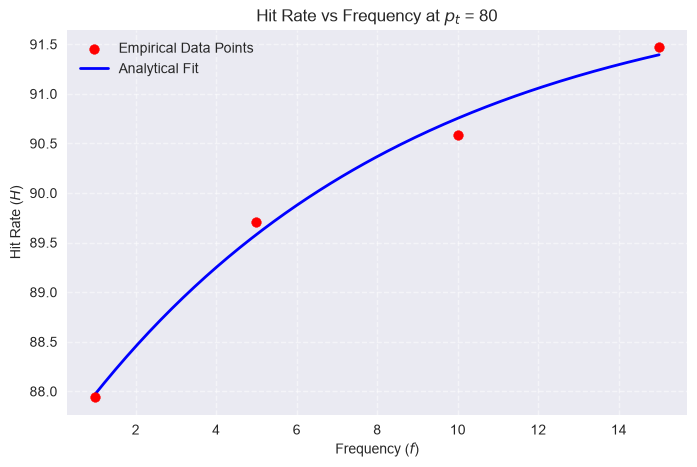

In [56]:
def asymptotic_exponential(f, A, B, k):
    """ Model: H(f) = A - B * exp(-k * f) """
    return A - B * np.exp(-k * f)

csv_files = [
    "./outputs/forecast_evaluation_metrics_1_R_0.25.csv",
    "./outputs/forecast_evaluation_metrics_5_R_0.25.csv",
    "./outputs/forecast_evaluation_metrics_10_R_0.25.csv",
    "./outputs/forecast_evaluation_metrics_15_R_0.25.csv"
]
combined_df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
CHOSEN_PT = 80

slice_df = combined_df[combined_df['p_t'] == CHOSEN_PT]
grouped_slice = slice_df.groupby('frequency')['hit_rate'].mean().reset_index()
frequencies = grouped_slice['frequency'].astype(float).values
hit_rates = grouped_slice['hit_rate'].astype(float).values

# Fit the Analytical Function
initial_guesses = [100, 50, 0.1]
popt, pcov = curve_fit(asymptotic_exponential, frequencies, hit_rates, p0=initial_guesses, maxfev=10000)
A_fit, B_fit, k_fit = popt

# Evaluate Fit Quality
predictions = asymptotic_exponential(frequencies, A_fit, B_fit, k_fit)
r2 = r2_score(hit_rates, predictions)

print("=" * 50)
print(f"ANALYTICAL FUNCTION DERIVED FOR p_t = {CHOSEN_PT}")
print("=" * 50)
print(f"H(f) = {A_fit:.4f} - {B_fit:.4f} * e^(-{k_fit:.4f} * f)")
print(f"R-squared Accuracy Score: {r2:.4f}")
print("=" * 50)

plt.figure(figsize=(8, 5))
plt.scatter(frequencies, hit_rates, color='red', zorder=3, label='Empirical Data Points')

f_smooth = np.linspace(frequencies.min(), frequencies.max(), 200)
h_smooth = asymptotic_exponential(f_smooth, A_fit, B_fit, k_fit)
plt.plot(f_smooth, h_smooth, color='blue', linewidth=2, label=f'Analytical Fit')

plt.title(f'Hit Rate vs Frequency at $p_t$ = {CHOSEN_PT}', fontsize=12)
plt.xlabel('Frequency ($f$)', fontsize=10)
plt.ylabel('Hit Rate ($H$)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### False alarm rate

FAR should fall with $f$ toward a floor, so it is fitted with an exponential decay, with all parameters constrained to be non-negative:

$$FAR(f) = A\,e^{-kf} + C$$

$C$ is the floor FAR approaches with very frequent sampling, $A + C$ is the FAR extrapolated to $f = 0$, and $k$ is the decay rate.

ANALYTICAL FUNCTION DERIVED FOR FALSE ALARM RATE (p_t = 80)
FAR(f) = 0.2329 * e^(-0.3036 * f) + 0.0000
R-squared Accuracy Score: 0.9914


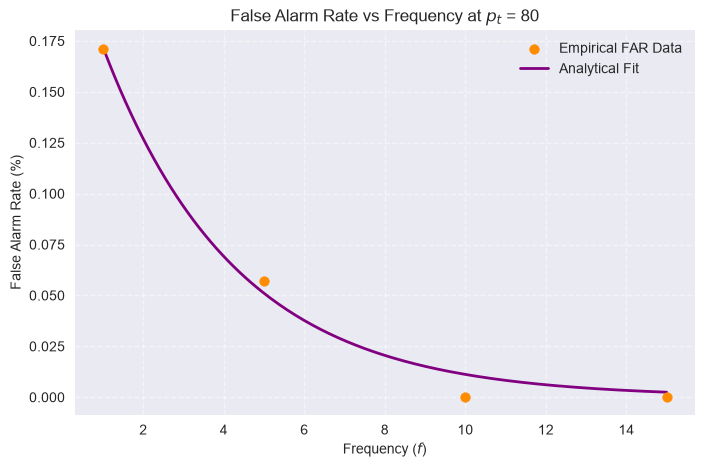

In [57]:
def exponential_decay(f, A, k, C):
    """ Model: FAR(f) = A * exp(-k * f) + C """
    return A * np.exp(-k * f) + C

csv_files = [
    "./outputs/forecast_evaluation_metrics_1_R_0.25.csv",
    "./outputs/forecast_evaluation_metrics_5_R_0.25.csv",
    "./outputs/forecast_evaluation_metrics_10_R_0.25.csv",
    "./outputs/forecast_evaluation_metrics_15_R_0.25.csv"
]
combined_df = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
CHOSEN_PT = 80

slice_df = combined_df[combined_df['p_t'] == CHOSEN_PT]
grouped_slice = slice_df.groupby('frequency')['false_alarm_rate'].mean().reset_index()
frequencies = grouped_slice['frequency'].astype(float).values
far_values = grouped_slice['false_alarm_rate'].astype(float).values

# Fit the Analytical Function
initial_guesses = [max(far_values), 0.1, 0.0]
param_bounds = ((0, 0, 0), (np.inf, np.inf, np.inf))
popt, pcov = curve_fit(exponential_decay, frequencies, far_values, p0=initial_guesses, bounds=param_bounds, maxfev=5000)
A_fit, k_fit, C_fit = popt

# Evaluate Fit Quality
predictions = exponential_decay(frequencies, A_fit, k_fit, C_fit)
r2 = r2_score(far_values, predictions)

# Print the Final Explicit Formula
print("=" * 50)
print(f"ANALYTICAL FUNCTION DERIVED FOR FALSE ALARM RATE (p_t = {CHOSEN_PT})")
print("=" * 50)
print(f"FAR(f) = {A_fit:.4f} * e^(-{k_fit:.4f} * f) + {C_fit:.4f}")
print(f"R-squared Accuracy Score: {r2:.4f}")
print("=" * 50)

# Visual Validation
plt.figure(figsize=(8, 5))
plt.scatter(frequencies, far_values, color='darkorange', zorder=3, label='Empirical FAR Data')

f_smooth = np.linspace(frequencies.min(), frequencies.max(), 200)
far_smooth = exponential_decay(f_smooth, A_fit, k_fit, C_fit)
plt.plot(f_smooth, far_smooth, color='purple', linewidth=2, label=f'Analytical Fit')

plt.title(f'False Alarm Rate vs Frequency at $p_t$ = {CHOSEN_PT}', fontsize=12)
plt.xlabel('Frequency ($f$)', fontsize=10)
plt.ylabel('False Alarm Rate (%)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### 9. Visualizations

### 9.1 Skill across frequency and alarm threshold

Contour map of the trial-averaged hit rate (or FAR, chosen with `metric_eval`) over sampling frequency and alarm threshold $p_t$. Section 8 fits a single row of this map ($p_t = 60$). The full map shows how the effect of sampling frequency changes as the alarm threshold becomes stricter.

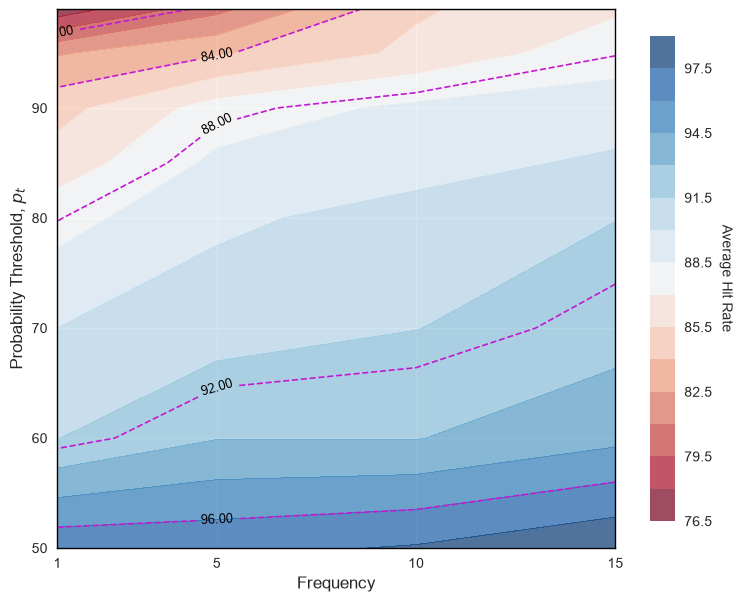

In [58]:
# Colormap of the HR and FAR functions
csv_file_1 = "./outputs/forecast_evaluation_metrics_1_R_0.25.csv"
csv_file_2 = "./outputs/forecast_evaluation_metrics_5_R_0.25.csv"
csv_file_3 = "./outputs/forecast_evaluation_metrics_10_R_0.25.csv"
csv_file_4 = "./outputs/forecast_evaluation_metrics_15_R_0.25.csv"

df1 = pd.read_csv(csv_file_1)
df2 = pd.read_csv(csv_file_2)
df3 = pd.read_csv(csv_file_3)
df4 = pd.read_csv(csv_file_4)

# Combine them vertically into a single dataframe
combined_df = pd.concat([df1, df2, df3, df4], ignore_index=True)

metric_eval = 'hit_rate' # Choose "hit_rate" or "false_alarm_rate"
grouped_df = combined_df.groupby(['p_t', 'frequency'])[metric_eval].mean().reset_index()
pivot_df = grouped_df.pivot(index='p_t', columns='frequency', values=metric_eval)

X = pivot_df.columns.astype(float).values
Y = pivot_df.index.astype(float).values
Z = pivot_df.values

# Generate the Contour Heatmap Plot
fig, ax = plt.subplots(figsize=(9, 7))
heatmap = ax.contourf(X, Y, Z, levels=20, cmap='RdBu', alpha=0.7)
cbar = fig.colorbar(heatmap, ax=ax, shrink=0.9, aspect=20,)
label="Average Hit Rate" if metric_eval=="hit_rate" else "Average FAR"
cbar.set_label(label, rotation=270, labelpad=15, fontsize=10)
cbar.ax.tick_params(labelsize=10)

contour_lines = ax.contour(X, Y, Z, levels=5, colors="#c319d2", linewidths=1.2, linestyles='dashed')
ax.clabel(contour_lines, inline=True, fmt='%.2f', fontsize=9, colors='k')

ax.set_xlabel('Frequency', fontsize=12)
ax.set_ylabel('Probability Threshold, $p_t$', fontsize=12)
ax.set_xticks(X)
ax.tick_params(axis='both', which='major', labelsize=10)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)
    spine.set_color('black')

# plt.savefig(f"{metric_eval} heatmap", dpi=150, bbox_inches='tight')

### 9.2 EnKF states during assimilation

The remaining cells replay the EnKF from the saved Parquet files, one assimilation at a time. They need a run made with `viz=True` (Section 5), which stores every assimilation step of each window with both the predicted state (`x_forecast`: after process noise, before the update) and the estimated state (`value`: after the update). With `viz=False` only the first assimilation of each window is stored and there is no predicted state.

`load_enkf_window` reads one window from the `.parquet` (one window per file, because Section 6 runs with `segment_size=1`). It returns the state timestamps and, for each requested `obs_step`, the 95% Confidence Interval of the estimated state and, if stored, the predicted state.

In [59]:
def load_enkf_window(folder_path, window, obs_steps=None):
    """
    Reads one window's EnKF output from the .parquet.
    Returns the window's state timestamps and the 95% CIs of the analysis (`value`) and, if stored, the forecast (`x_forecast`)
    for every requested obs_step.
    """
    seg_path = os.path.join(folder_path, f"output_seg{window:05d}.parquet")
    filters = [("window_id", "==", window)]
    if obs_steps is not None:
        filters.append(("obs_step", "in", list(obs_steps)))
    df = pd.read_parquet(seg_path, filters=filters)
    if df.empty:
        stored = sorted(pd.read_parquet(seg_path, columns=["obs_step"])["obs_step"].unique().tolist())
        raise ValueError(f"obs_steps {obs_steps} not found in {seg_path}. Stored obs_steps: {stored}")
    df = df.sort_values(["obs_step", "ensemble_id", "step"])

    steps = df["obs_step"].unique()
    n_ens = df["ensemble_id"].nunique()
    state_length = df["step"].nunique()

    def ci(col):
        X = df[col].to_numpy().reshape(len(steps), n_ens, state_length)  # (obs_step, ensemble, step)
        lower, upper = np.percentile(X, [2.5, 97.5], axis=1)
        return lower, upper

    win = {"obs_steps": steps, "timestamps": pd.DatetimeIndex(df["timestamp"].iloc[:state_length])}
    win["lower_ci"], win["upper_ci"] = ci("value")
    if "x_forecast" in df.columns:
        win["lower_f"], win["upper_f"] = ci("x_forecast")
    return win


Choose the run to plot by frequency and trial, then load its ground truth and the noisy measurements the EnKF assimilated. The folder name also uses `sigma` and `R` from Section 5.

In [40]:
current_frequency = 5
trial = 0
folder_path = f'./outputs/EnKF Frequency {current_frequency} Sigma {sigma} R {R} Trial {trial}'

obs_df_dedup = pd.read_parquet(os.path.join(folder_path, 'obs_df_dedup.parquet'))          # Ground Truth
obs_df_synthetic = pd.read_parquet(os.path.join(folder_path, 'obs_df_synthetic.parquet'))  # Noisy measurements fed to the EnKF

**One assimilation step.** Set `window` and `index` (the assimilation within the window, starting at 0). The plot shows:

- **Star:** the measurement being assimilated at this step.
- **Left of the star (past):** times that have already been observed. They receive no process noise, so the predicted and estimated bands nearly coincide there.
- **Right of the star (future):** times not yet observed. The predict step adds process noise here, so the predicted band is wider than the estimated band, which the measurement has narrowed.
- The ground truth and the noisy measurements.

The legend uses filtering notation with $k$ = `index + 1`: $X(k \mid k-1)$ is the predicted state before measurement $k$ is assimilated, and $X(k \mid k)$ is the estimated state after.

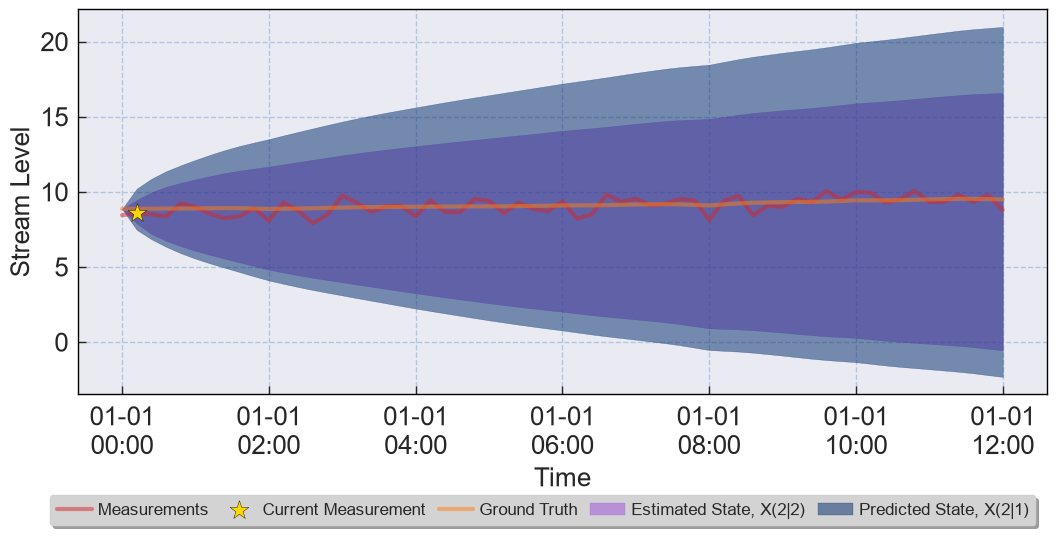

In [ ]:
fontsize=19
linewidth=3
plt.style.use('seaborn-v0_8')
fig, ax1 = plt.subplots(figsize=(12.5,5))

window = 0 # select the window we want to plot
index = 1 # within the window, select which assimilation we want to plot. 0:first assimilation, 1: second assimilation and so on

win = load_enkf_window(folder_path, window, obs_steps=[index])
state_times = win["timestamps"]
t0, t1 = state_times[0], state_times[-1]

y = obs_df_synthetic.loc[t0:t1, "Instantaneous Stream Level (ft)"]
y_ground_truth = obs_df_dedup.loc[t0:t1, "Instantaneous Stream Level (ft)"]

# Plot noisy measurements
ax1.plot(y.index, y, alpha=0.5, color="tab:red", linewidth=linewidth, label="Measurements")
ax1.scatter(y.index[index], y.iloc[index], marker='*', color='gold', s=200,
         edgecolors='black', label="Current Measurement", zorder=5)

# Plot Ground Truth Measurements
ax1.plot(y_ground_truth.index, y_ground_truth, alpha=0.5, color="tab:orange", linewidth=linewidth, label="Ground Truth")

# Plot the Confidence Intervals
ax1.fill_between(state_times, win["lower_ci"][0], win["upper_ci"][0], color="#9d4edd", alpha=0.5, label=f'Estimated State, X({index+1}|{index+1})')
if "lower_f" in win:
    ax1.fill_between(state_times, win["upper_f"][0], win["lower_f"][0],
                     alpha=0.5, color="#00296b", label=f"Predicted State, X({index+1}|{index})")

# Plotting Style
ax1.set_xlabel(f"Time", fontsize=fontsize)
ax1.set_ylabel(f"Stream Level", fontsize=fontsize)
ax1.tick_params(axis='both', which='both', direction='in', length=6, labelsize=fontsize)
for spine in ax1.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)
    spine.set_color('black')
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d\n%H:%M'))
ax1.grid(True, linestyle='--', alpha=0.95, color='#b0c4de', axis='both')
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles=handles, labels=labels, loc='upper center', bbox_to_anchor=(0.48, -0.24), ncols=5,
            fancybox=True, shadow=True, frameon=True, facecolor='lightgrey', prop={'size':12.5}, handletextpad=0.35, columnspacing=0.75)


**Animation over a whole window.** Replays every stored assimilation of `window`, one frame per measurement. The star steps through the measurements and both bands are redrawn each frame, so the future band can be seen narrowing as measurements arrive. The video is saved to `outputs/enkf_assimilation_window_{window}_frequency_{f}_R_{R}_parquet.mp4` at 1 frame per second; writing MP4 requires `ffmpeg` on the system path.

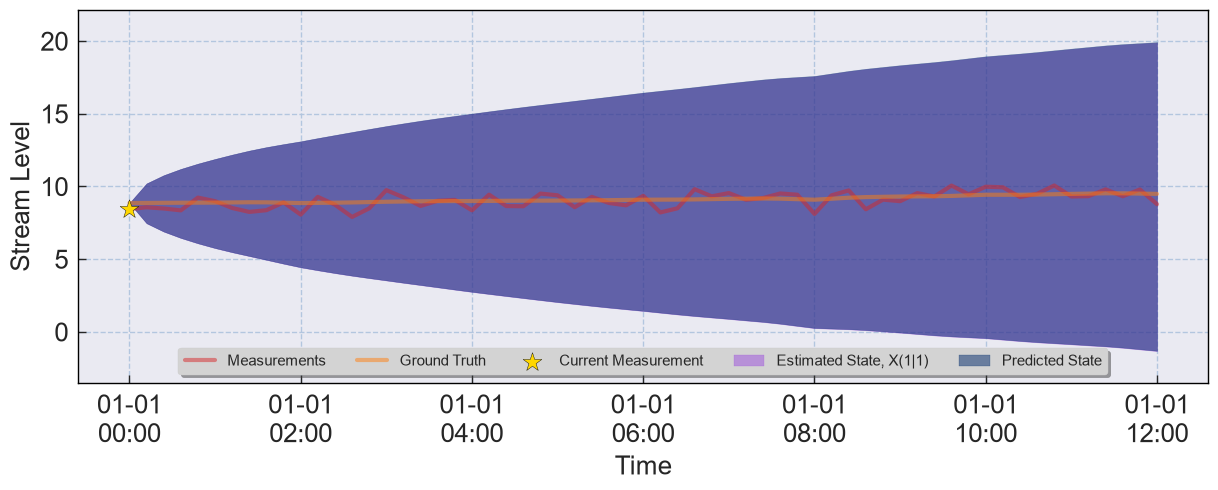

In [ ]:
fontsize = 19
linewidth = 3
plt.style.use('seaborn-v0_8')
fig, ax1 = plt.subplots(figsize=(12.5, 5))
fig.subplots_adjust(bottom=0.3)

window = 0 # Select the window we want to plot
win = load_enkf_window(folder_path, window)
state_times = win["timestamps"]
t0, t1 = state_times[0], state_times[-1]
if len(win["obs_steps"]) == 1:
    print(f"Only obs_step {win['obs_steps'][0]} is stored for window {window}; the video will have a single frame.")

y = obs_df_synthetic.loc[t0:t1, "Instantaneous Stream Level (ft)"]
y_ground_truth = obs_df_dedup.loc[t0:t1, "Instantaneous Stream Level (ft)"]

ax1.plot(y.index, y, alpha=0.5, color="tab:red", linewidth=linewidth, label="Measurements")
ax1.plot(y_ground_truth.index, y_ground_truth, alpha=0.5, color="tab:orange", linewidth=linewidth, label="Ground Truth")

ax1.set_xlabel("Time", fontsize=fontsize)
ax1.set_ylabel("Stream Level", fontsize=fontsize)
ax1.tick_params(axis='both', which='both', direction='in', length=6, labelsize=fontsize)

for spine in ax1.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)
    spine.set_color('black')
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d\n%H:%M'))
ax1.grid(True, linestyle='--', alpha=0.95, color='#b0c4de', axis='both')

star = ax1.scatter([], [], marker='*', s=200, edgecolors='black', zorder=5, color='gold', label='Current Measurement')
analysis_fill = None
forecast_fill = None

def update(frame):
    global analysis_fill, forecast_fill

    if analysis_fill is not None:
        analysis_fill.remove()
    if forecast_fill is not None:
        forecast_fill.remove()

    index = win["obs_steps"][frame]

    # Update measurement star
    star.set_offsets([[mdates.date2num(y.index[index]), y.iloc[index]]])

    # Analysis CI
    analysis_fill = ax1.fill_between(state_times, win["lower_ci"][frame], win["upper_ci"][frame],
        color="#9d4edd", alpha=0.5, label=f'Estimated State, X({index+1}|{index+1})')

    # Forecast CI
    if "lower_f" in win:
        forecast_fill = ax1.fill_between(state_times, win["upper_f"][frame], win["lower_f"][frame],
            alpha=0.5, color="#00296b", label=f"Predicted State")
    handles, labels = ax1.get_legend_handles_labels()
    ax1.legend(handles, labels, loc='lower center', ncol=6, frameon=True, fancybox=True, facecolor='lightgrey', shadow=True, prop={'size':11})
    return star,

n_frames = len(win["obs_steps"])
ani = FuncAnimation(fig, update, frames=n_frames, interval=1000, repeat=True, blit=False)
fig.tight_layout()
ani.save(f"./outputs/enkf_assimilation_window_{window}_frequency_{current_frequency}_R_{R}_parquet.mp4", dpi=150, fps=1)


### 10. Energy-aware sampling: MPC + online EnKF

Sections 6–8 measured how forecast skill depends on sampling frequency. This section uses that relationship online. A model predictive controller (MPC) decides, every hour, how many measurements per hour the sensor node takes. Sampling more often makes the forecast more valuable but drains the node's battery, which a small solar panel recharges. The controller weighs the expected value of the forecast against the node's state of energy (SoE).

How the pieces connect:

1. The offline fits $HR(f)$ and $FAR(f)$ (Section 8) feed a cost–loss model that gives the expected value of the forecast at frequency $f$, given the probability $P$ that an event occurs (Section 10.4).
2. The online EnKF supplies $P$ for each of the next 12 hours from its current ensemble (Section 10.8).
3. Every hour, the MPC chooses frequencies for the next 12 hours by trading forecast value against SoE. It applies only the first, and the EnKF assimilates the measurements taken at that rate (Sections 10.6 and 10.9).

### 10.1 Controller and energy model parameters

| Parameter | Value | Meaning |
|---|---|---|
| `lowerbound_fs`, `upperbound_fs` | 1, 15 | Bounds $f_{\min}$, $f_{\max}$ on the sampling frequency (measurements per hour) |
| `delta_t` | 1 | Length of one control window (h), also `window_size` |
| `L` | 2 | Loss when an event occurs |
| `L_a` | 1 | Part of that loss avoided by acting on a warning |
| `C` | 0.2 | Cost of acting on a warning |
| `zeta` | 0 | Discount rate over the MPC horizon (0 = no discounting) |
| `base_date` | 2021-01-01 | Start time of the run |
| `current_phases` | `[-0.00143, -0.22, -0.22]` | Current drawn when idle, sensing and transmitting (A; negative = discharge) |
| `charge_capacity` | 2.75 | Battery capacity (Ah) |
| `length_of_sense_event` | 13 | Duration of one measurement (s) |
| `length_of_transmit_event` | 4.12 | Duration of one transmission (s) |
| `harvesting_Schedule` | `[(1, True)]` | Slices of a window as (duration in h, harvesting on) |
| `lut_discharge` | `data/voltage_vs_SoC_LUT.csv` | Battery open-circuit voltage vs SoC, interpolated by `ocv_interpolator` |

In [60]:
# Optimizer Parameters
upperbound_fs = 15 # Bounds
lowerbound_fs = 1
delta_t = 1
L_a = 1 # Avoidable losses when event occurs
C = 0.2 # Cost of taking action
L = 2 # Total loss when event occurs

# Discount Parameters
zeta = 0
discount_denom = 1 + zeta

base_date = datetime.datetime(2021, 1, 1, 0, 0)
window_size = delta_t

# Consumption Parameters
current_phases = np.array([-0.00143, -0.22, -0.22])
charge_capacity = 2.75 # Ah
length_of_sense_event = 13
length_of_transmit_event = 4.12

# Energy Harvest Parameters
harvesting_Schedule = np.array([
    (1, True)
] * delta_t)

lut_discharge = pd.read_csv('./data/voltage_vs_SoC_LUT.csv')
soc_values = lut_discharge.iloc[:, 0].values / 100
ocv_values = lut_discharge.iloc[:, 1].values
ocv_interpolator = interp1d(soc_values, ocv_values, kind='linear', fill_value='extrapolate')

### 10.2 Battery and energy model

The battery is tracked by coulomb counting and converted to energy through its open-circuit voltage (OCV) curve.

- `estimate_energy_capacity(soc)`: energy left in the battery (J) at state of charge `soc` (0–1), integrating the OCV curve from the 1.5% minimum SoC: $E(s) = 3600\,Q_{bat}\int_{0.015}^{s} V_{oc}(s')\,ds'$, with $Q_{bat}$ = `charge_capacity` in Ah. `nominal_energy_capacity` is the energy of a full battery.
- `cc_method`: coulomb counting. Updates the SoC (%) after drawing a current for a given duration.
- `calculate_harvested_energy`: solar energy harvested (J) from a given power (W) over a duration (h), at 5% conversion efficiency.
- `energy_ratio`: simulates one window at sampling frequency `f_s_k` and transmission frequency `f_t_k`. Each measurement takes 13 s of sensing and each transmission 4.12 s; the rest of the window is idle. It drains the battery phase by phase, adds the forecast solar harvest, and returns the SoE at the end of the window (energy left plus harvest, as % of `nominal_energy_capacity`) and the SoC after recharging.

In [61]:
def estimate_energy_capacity(soc):
    '''
    Returns the estimated energy left, in J, given the SoC calculated using the CC Method.
    '''
    soc_for_integration = np.linspace(0.015, soc, 1000)  # 1.5% is the minimum permitted SoC.
    ocv_for_integration = ocv_interpolator(soc_for_integration)
    integral_result = np.trapezoid(ocv_for_integration, soc_for_integration)
    estimated_energy_left = charge_capacity * integral_result * 3600

    return estimated_energy_left
nominal_energy_capacity = estimate_energy_capacity(1)

In [62]:
def cc_method(previous_soc, phase_duration, phase_current):
    soc_present = previous_soc + (1/charge_capacity) * (phase_duration * phase_current * 100)
    return max(0, min(100, soc_present))

In [63]:
def calculate_harvested_energy(power, duration, efficiency=0.05):
    '''Expected Amount of Energy Harvested in window k, returns in Joules'''
    harvested_energy = power * duration * efficiency
    return harvested_energy * 3600

In [64]:
def energy_ratio(soc, f_s_k, f_t_k, window, peak_power):
    '''
    Calculates the State of Energy at the end of the k-th window given a set of frequency (f_s_k, f_t_k) and energy harvest.
    soc: The state of charge
    f_s_k, f_t_k: The set of decision variables
    window: The time index in which we are operating, aka k
    peak_power: The peak power harvested
    '''
    durations = harvesting_Schedule[:, 0]
    harvest_flags = harvesting_Schedule[:, 1]
    harvested_energy = 0
    current_soc = soc
    sense_duration = (length_of_sense_event/3600 * (f_s_k * durations))
    transmit_duration = (length_of_transmit_event/3600 * (f_t_k * durations))
    idle_duration = durations - sense_duration - transmit_duration
    for i in range(len(durations)):
        # ----------------------------
        # Battery discharge
        # ----------------------------
        current_soc = cc_method(current_soc, sense_duration[i], current_phases[1])
        current_soc = cc_method(current_soc, transmit_duration[i], current_phases[2])
        current_soc = cc_method(current_soc, idle_duration[i], current_phases[0])

        # ----------------------------
        # Harvesting
        # ----------------------------
        if harvest_flags[i]:
            # for _ in range(durations[i]): # For when hour=1
            harvested_energy += calculate_harvested_energy(peak_power[window][i], 1)

        # ----------------------------
        # State of Energy
        # ----------------------------        
        energy_at_end_of_slice = estimate_energy_capacity(current_soc / 100)
        energy_ratio = (energy_at_end_of_slice + harvested_energy)/(nominal_energy_capacity) * 100
        energy_ratio = max(0, min(100, energy_ratio)) # This is the SoE

        # ----------------------------
        # Recharge battery
        # ----------------------------
        harvested_charge = harvested_energy / 3.6   # This is C, 3.6 is the Nominal Voltage
        current_soc = ((0.01 * current_soc * charge_capacity) + (harvested_charge / 3600)) / (charge_capacity)*100  ### This is from 0 - 100
        current_soc = max(0, min(100, current_soc))
        harvested_energy = 0
    return energy_ratio, current_soc

### 10.3 Skill model

`hit_rate_function` and `far_function` are the Section 8 fits, hard-coded as closed-form functions of $f$ (in %).

In [65]:
def hit_rate_function(frequency):
    ''' Hit Rate as a function of freuqency'''
    return 92.165 - 4.7277*np.exp(-0.1209*frequency) # p_t=0.8
    # return 94.9237 - 3.6367*np.exp(-0.0864*frequency) # p_t=0.6

In [66]:
def far_function(frequency):
    ''' False Alarm Rate as a function of freuqency'''
    return 0.2329*np.exp(-0.3036*frequency) + 0 # p_t=0.8
    # return 0.2029*np.exp(-0.0865*frequency) + 0 # p_t=0.6

### 10.4 Value of the forecast: cost–loss model

A warning lets a user act at cost $C$. An event causes loss $L$, of which $L_a$ is avoided by acting. With event probability $P$, and hit rate and false alarm rate as fractions, the expected expense of relying on the forecast at frequency $f$ is

$$E(f) = (C + L - L_a)\,HR(f)\,P + C\,FAR(f)\,(1-P) + L\,\bigl(1 - HR(f)\bigr)\,P$$

The three terms are hits (act, pay $C$ and still lose $L - L_a$), false alarms (act for nothing) and misses (lose $L$). `expected_value_of_eps` returns the saving from sampling at $f$ instead of the minimum frequency $f_{\min}$:

$$V(f, P) = E(f_{\min}) - E(f) = P\,(L_a - C)\,\bigl[HR(f) - HR(f_{\min})\bigr] + C\,(1 - P)\,\bigl[FAR(f_{\min}) - FAR(f)\bigr]$$

Each extra hit saves $L_a - C$ and each avoided false alarm saves $C$. With these parameters the value grows with $P$, so sampling faster pays off most when the EnKF expects an event. `model` can pass other skill curves as a dict with keys `"hit_rate"` and `"false_alarm_rate"` for other geographical sites; `None` uses the Section 10.3 functions.

`normalize_eveps` scales $V$ to $[0, 1]$, using $V(f_{\max}, P = 1)$ as the maximum and $V(f_{\min}, P = 0) = 0$ as the minimum, so it can be combined with the SoE term in the MPC objective.

In [67]:
def expected_value_of_eps(L, L_a, C, frequency, P, model):
    # '''
    # Calculates the REV of the EPS at `frequency` with the assimilated belief `P` 
    # P: Belief that an event will occur, [0, 1]
    # '''

    if model is None:
        hit_fn = hit_rate_function
        far_fn = far_function
    else:
        hit_fn = model.get("hit_rate")
        far_fn = model.get("false_alarm_rate")
        
    E_naive = (C + L - L_a) * (hit_fn(lowerbound_fs)/100 * P) + (far_fn(lowerbound_fs)/100 * C * (1 - P)) + (P * L * (1 - hit_fn(lowerbound_fs)/100))
    E_nominal = (C + L - L_a) * (hit_fn(frequency)/100 * P) + (far_fn(frequency)/100 * C * (1 - P)) + (P * L * (1 - hit_fn(frequency)/100))
    return E_naive - E_nominal

In [68]:
def normalize_eveps(value, model):
    max_value = expected_value_of_eps(L, L_a, C, upperbound_fs, 1, model)
    min_value = expected_value_of_eps(L, L_a, C, lowerbound_fs, 0, model)

    if (value > max_value) or (value < min_value):
        ValueError("VoI out of normalization bounds!")
    return (value - min_value) / (max_value - min_value)

### 10.5 Solar harvest forecast

`update_harvest_belief` forecasts the power harvested in each of the next windows from the actual NASA POWER GHI record, so the controller knows future sunlight exactly. The GHI at the start of each hour is scaled by a 0.01 m² panel and an availability factor of 0.5. `compute_belief` returns the GHI values in a time range.

In [87]:
def compute_belief(start_date, end_date, solar_df):
    """
    Computes harvest belief by finding the max ALLSKY_SFC_SW_DWN in a given date range.
    current_window: Current MPC window.
    start_date, end_date: Date range to consider.
    """
    mask = (solar_df['datetime'] >= start_date) & (solar_df['datetime'] <= end_date)
    filtered_df = solar_df[mask].sort_values('datetime')
    return filtered_df['ALLSKY_SFC_SW_DWN'].values

In [88]:
def update_harvest_belief(current_window, total_windows, base_date, solar_df):
    '''
    Updates the beliefs about the future harvest using ground truth values.
    Assumes a solar panel size of 0.01 m^2
    '''
    panel_size=0.01
    energy_availability = 0.5
    beliefs = []
    start_dates = [base_date + pd.Timedelta(hours=(current_window + i) * window_size) for i in range(total_windows)]
    end_dates = [start + pd.Timedelta(hours=window_size) for start in start_dates]
    max_ghi_values = [compute_belief(S, E, solar_df) for S, E in zip(start_dates, end_dates)]
    beliefs = [max_ghi*panel_size*energy_availability for max_ghi in max_ghi_values]

    # Comment this when not simulating worst-case scenario
    # beliefs = [0]*total_windows
    return beliefs

### 10.6 The MPC problem

At each window the controller chooses sampling frequencies $f_0, \dots, f_{H-1}$ for the next $H$ windows by solving

$$\max_{f_0,\dots,f_{H-1}} \; \sum_{k=0}^{H-1} \frac{1}{(1+\zeta)^k}\left[ w_v\,\hat V(f_k, P_k) + w_e\,\frac{SoE_k}{100} - \left(\frac{f_k - f_{k-1}}{f_{\max}}\right)^2 \right]$$

subject to $f_{\min} \le f_k \le f_{\max}$ and $SoE_k \ge 0$% for every $k$.

$\hat V$ is the normalized forecast value (Section 10.4), $P_k$ the EnKF's event probability for lead hour $k$, $SoE_k$ the predicted SoE at the end of window $k$ (Section 10.2), and $f_{-1}$ the frequency applied in the previous window. The last term penalizes large jumps in frequency. Windows in which the battery is predicted to be empty add nothing, and every measurement is also transmitted ($f_t = f_s$). The weights are set in `run_mpc`: $w_v = 0.5$, $w_e = 0.5$.

- `energy_constraint`: the $SoE_k \ge 0$% constraint for each window in the horizon.
- `constr_f_s`: an optional equality constraint that pins every frequency to 8 measurements per hour, for comparing the MPC against a fixed-frequency baseline.
- `mpc_objective`: the objective above, negated (and scaled by 10) because SciPy minimizes.
- `get_mpc_diagnostics`: recomputes each term of the objective for the chosen frequencies, for logging.

In [89]:
def energy_constraint(params, effective_horizon, initial_soc, harvest_belief, epsilon=1):
    SoC = initial_soc
    f_s = params[:effective_horizon]
    # f_t = params[effective_horizon:]
    constraints = []
    for k in range(effective_horizon):
        E_value, SoC = energy_ratio(SoC, f_s[k], f_s[k], k, harvest_belief) # The value returned is in %
        constraints.append(E_value - epsilon)  # Ensure SoE >= epsilon
    return np.array(constraints)

In [90]:
def constr_f_s(params, effective_horizon):
    '''
    This constraint is used if we want to compare the nominal MPC against a baseline fixed frequency.
    Forces the MPC controller to always choose a fixed frequency.
    '''
    f_s = params[:effective_horizon]
    return f_s - 8.0

In [91]:
def mpc_objective(params, current_window, effective_horizon, initial_soc, weight_voi, weight_energy, weight_smooth, harvest_belief, baro, prev_applied_fs, model=None):
    """
    Objective function for MPC step.
    params: Decision variables (f_s and f_t) for the effective_horizon windows.
    current_window: Starting window index for the MPC step.
    effective_horizon: Number of windows to optimize (prediction horizon).
    initial_soc: Initial State of Charge at current_window.
    """
    SoC = initial_soc
    total_utility = 0

    f_s = params[:effective_horizon] # Effective horizon is the number of windows forward that we are looking into
    # f_t = params[effective_horizon:]
    mpc_objective.last_state = {'raw_values': [], 'norm_values': [], 'energies': []}
    for k in range(effective_horizon):
        discount_factor = 1 / (discount_denom ** k)  # Discounting is applied to the effective horizon of the MPC
        energy, cond = energy_ratio(SoC, f_s[k], f_s[k], window=k, peak_power=harvest_belief)

        if SoC > 0 and energy > 0:
                value = expected_value_of_eps(L, L_a, C, f_s[k], baro[k], model)
                norm_value = normalize_eveps(value, model)
                f_prev = prev_applied_fs if k == 0 else f_s[k - 1]
                smoothness_cost = weight_smooth * ((f_s[k] - f_prev) / upperbound_fs) ** 2                
                utility = (weight_voi * norm_value + weight_energy * (energy/100) - smoothness_cost) * discount_factor
                mpc_objective.last_state['raw_values'].append(value)
                mpc_objective.last_state['norm_values'].append(norm_value)
                mpc_objective.last_state['energies'].append(energy/100)
                total_utility += utility
        SoC = cond
    return -1e1*total_utility

In [92]:
def get_mpc_diagnostics(params, effective_horizon, initial_soc, harvest_belief, baro, prev_applied_fs, model):
    SoC = initial_soc

    raw_values = []
    norm_values = []
    energies = []
    smoothness_costs = []

    f_s = params[:effective_horizon]

    for k in range(effective_horizon):
        energy, cond = energy_ratio(SoC, f_s[k], f_s[k], window=k, peak_power=harvest_belief)
        if SoC > 0 and energy > 0:
            value = expected_value_of_eps(L, L_a, C, f_s[k], baro[k], model)
            norm_value = normalize_eveps(value, model)
            f_prev = (prev_applied_fs if k == 0 else f_s[k - 1])
            smoothness_cost = 1/3 * ((f_s[k] - f_prev) / upperbound_fs) ** 2

            raw_values.append(value)
            norm_values.append(norm_value)
            energies.append(energy / 100)
            smoothness_costs.append(smoothness_cost)
        else:
            raw_values.append(np.nan)
            norm_values.append(np.nan)
            energies.append(np.nan)
            smoothness_costs.append(np.nan)
        SoC = cond

    return {
        "value": np.array(raw_values),
        "norm_value": np.array(norm_values),
        "energy": np.array(energies),
        "smoothness_cost": np.array(smoothness_costs),
    }

### 10.7 Sensor emulator: `SensorEmulator`

Stands in for the sensor node. On creation it builds the truth at `max_frequency` samples per hour for `t_windows × step_hours` hours, and adds Gaussian noise with variance `R` to make the measurements, as in Section 6. The noise is drawn once from a fixed seed, so runs with different controllers see the same measurement noise.

- `generate_initial_forecast`: the starting ensemble at `initial_frequency`, built with `generate_confidence_fans` (Section 4.1).
- `get_window_data`: subsamples the measurements to the frequency the controller applied and returns those in window $k$ (both ends included), plus the timestamps of the full 12-hour forecast horizon on the same grid.

In [93]:
class SensorEmulator:
    def __init__(self, threat_data_raw, max_frequency=60, horizon_hours=12, step_hours=1, t_windows=5, R=0.25, seed=None, t=1000):
        """
        Emulates sensor sampling from raw threat data using master ground truth and noisy synthetic measurements
        """
        self.max_frequency = max_frequency
        self.max_freq_interval = 60 / max_frequency
        self.horizon_hours = horizon_hours
        self.step_hours = step_hours
        self.t_windows = t_windows
        self.R = R
        self.seed = seed
        self.t = t

        # 1. Generate master ground truth (highest frequency base dataset)
        master_tx_interval = np.full(t_windows * self.step_hours, self.max_freq_interval)
        master_obs_df = get_observational_data(threat_data_raw, master_tx_interval)
        self.master_obs_df_dedup = master_obs_df[~master_obs_df.index.duplicated(keep="first")] # Ground Truth at frequency of 60

        # 2. Add measurement noise to generate master synthetic dataset
        self.sensor_seed = np.random.default_rng(seed=self.seed)
        n_points_master = len(self.master_obs_df_dedup)
        master_noise = self.sensor_seed.normal(0, np.sqrt(self.R), n_points_master)

        self.master_synthetic_df = self.master_obs_df_dedup.copy() 
        self.master_synthetic_df["Instantaneous Stream Level (ft)"] += master_noise # Noisy Sensor Measurements

    def _get_target_rule(self, frequency):
        interval_seconds = int(round(3600.0 / frequency))
        return f"{interval_seconds}s"

    def generate_initial_forecast(self, initial_frequency=1, sigma=3, bias=(0, 0), n_samples=500, alpha=0.3,):
        """
        Generates initial confidence fans from ground truth as needed prior to step 0.
        """
        # target_rule = f"{60 / initial_frequency}min"
        target_rule = self._get_target_rule(initial_frequency)
        obs_df_dedup = self.master_obs_df_dedup.asfreq(target_rule, method="pad") # Ground Truth at desired frequency

        forecast_df = generate_confidence_fans(obs_df_dedup, sigma, bias, n_samples=n_samples, t=self.t, alpha=alpha,
                                                horizon_hours=self.horizon_hours, step_hours=self.step_hours, seed=self.seed,)
        return forecast_df

    def get_window_data(self, current_window, current_frequency, state_grid_frequency=None):
        sensing = current_frequency > 0
        grid_freq = current_frequency if sensing else state_grid_frequency
        if grid_freq is None or grid_freq <= 0:
            raise ValueError("state_grid_frequency must be > 0 when current_frequency is 0")

        target_rule = self._get_target_rule(grid_freq)
        obs_df_synthetic = self.master_synthetic_df.asfreq(target_rule, method="pad")
        obs_df_dedup = self.master_obs_df_dedup.asfreq(target_rule, method="pad")
        start_time = obs_df_dedup.index[0] + pd.Timedelta(hours=current_window * self.step_hours)

        if sensing:
            obs_end_time = start_time + pd.Timedelta(hours=self.step_hours)
            obs_df_synthetic_window = obs_df_synthetic.loc[start_time:obs_end_time]
        else:
            obs_df_synthetic_window = obs_df_synthetic.iloc[0:0]

        # Full 12-hour horizon timestamps
        horizon_end_time = start_time + pd.Timedelta(hours=self.horizon_hours)
        horizon_timestamps = obs_df_dedup.loc[start_time:horizon_end_time].index.to_series()
        return obs_df_synthetic_window, horizon_timestamps

### 10.8 Online EnKF: `EnsembleKalmanFilter`

A stateful version of the Section 4 EnKF that advances one control window at a time. The state is again the forecast trajectory over the 12-hour horizon, and the measurement grid changes whenever the controller changes the frequency.

- `initialize_ensemble`: loads the first window of the initial forecast.
- `prepare_window_state`: the handover at the start of window $k > 0$. If the frequency has changed, the ensemble is linearly interpolated onto the new measurement grid. The first hour, now in the past, is dropped, and `generate_forecast_from_kf_estimate` (Section 4.2) appends a fresh final hour, so the analysed 11-hour overlap carries into the new window.
- `assimilate_window`: assimilates the window's measurements one at a time with the predict and update steps of Section 4.3. The measurement at the end of the window is left for the next window, where it is the first. The 95% CI of the predicted and estimated states after each measurement is stored in `history`.
- `get_horizon_event_probabilities`: the event beliefs $P_k$ for the MPC. The state is split into 1-hour blocks of lead time, and $P_k$ is the fraction of members that reach the water level threshold at any time in block $k$.

In [94]:
class EnsembleKalmanFilter:
    """Stateful Ensemble Kalman Filter for online MPC integration."""
    def __init__(self, n_ens=500, R=0.25, Q=3.0, alpha=0.3, sigma=3.0, bias=(0, 0), frequency=1.0, seed=None,
                 t_corr=10, process_noise=False, horizon_hours=12, shared_error_scale=0.0, shared_error_seed=2026):
        self.n_ens = n_ens
        self.R = R
        self.Q = Q
        self.alpha = alpha
        self.sigma = sigma
        self.bias = bias
        self.frequency = frequency
        self.rng = np.random.default_rng(seed)
        self.seed = seed
        self.t_corr = t_corr  # Correlation length (h) of the forecast model error and of Q
        self.process_noise = process_noise
        self.shared_error_scale = shared_error_scale
        self.shared_error_seed = shared_error_seed
        self.horizon_hours = horizon_hours

        self.X_a = None  # Ensemble matrix: shape (state_length, n_ens)
        self.current_window = 0
        self.history = []

    def initialize_ensemble(self, forecast_df, init_state_length):
        """Initializes the analysis ensemble X_a from initial forecast data."""
        self.X_a = np.zeros((init_state_length, self.n_ens))
        for i in range(self.n_ens):
            v_k = forecast_df.loc[(forecast_df["ensemble_id"] == i) & (forecast_df["window_id"] == 0)]["value"].values
            self.X_a[:init_state_length, i] = v_k[:init_state_length]

    def prepare_window_state(self, prev_num_obs, horizon_timestamps, obs_df_clean, window_id):
        """
        Handover step: At start of window k > 0, update X_a ensemble using forecast from previous filtered state
        """
        new_state_length = len(horizon_timestamps)
        current_state_length = self.X_a.shape[0]
        total_seconds = (horizon_timestamps.iloc[-1] - horizon_timestamps.iloc[0]).total_seconds()
        horizon_hours = round(total_seconds / 3600.0)

        if current_state_length != new_state_length:
            t_old = np.linspace(0, horizon_hours, current_state_length)
            t_new = np.linspace(0, horizon_hours, new_state_length)
            interpolator = interp1d(t_old, self.X_a, axis=0, kind='linear', fill_value="extrapolate")
            X_a_resampled = interpolator(t_new)
        else:
            X_a_resampled = self.X_a

        # 3. Trim the first hour (which is now in the past).
        target_time = horizon_timestamps.iloc[0] + pd.Timedelta(hours=1) # VERY IMPORTANT: MAKE SURE THIS IS EQUAL TO STEP_HOURS
        f_new = np.argmin(np.abs(horizon_timestamps - target_time))

        filtered_state_raw = X_a_resampled[f_new:, :]
        print(rf"Regenerating Forecasts with $\sigma$: {self.sigma}, $\alpha$: {self.alpha}")

        # x0 = X_a_resampled[f_new, :]   # analysis ensemble at the new window's start time
        # self.X_a = generate_forecast_from_analysis(x0, horizon_timestamps, obs_df_clean, sigma=self.sigma, alpha=self.alpha, t_corr=self.t_corr, lam=self.lam, rng=self.rng)

        shared_z = None
        if self.shared_error_scale > 0:
            shared_z = np.random.default_rng([self.shared_error_seed, window_id]).standard_normal()

        forecast_df = generate_forecast_from_kf_estimate(
            filtered_state_raw,
            horizon_timestamps,
            obs_df_clean,
            window_id=window_id,
            sigma=self.sigma,
            alpha=self.alpha,
            t=1000,
            n_ens=self.n_ens,
            rng=self.rng,
            # seed = self.seed,
            bias=self.bias,
            shared_z=shared_z,
            shared_scale=self.shared_error_scale,
        )

        filtered_window_df = forecast_df[forecast_df["window_id"] == window_id]
        X_ens_matrix = filtered_window_df.pivot(index="step", columns="ensemble_id", values="value").values
        # state_length = len(horizon_timestamps)
        self.X_a = X_ens_matrix[:new_state_length, :]

    def _build_process_noise_Q(self, state_length, current_obs_idx):
        """Constructs process noise covariance Q for the forecast part of the state."""
        epsilon = 1e-6
        full_Q = np.eye(state_length) * epsilon
        num_future = state_length - current_obs_idx

        if num_future > 0:
            dt = 1.0 / self.frequency
            future_times = np.arange(num_future) * dt
            # Process noise kernel and growth martingale
            kernel_v = kernel(future_times, future_times, t=self.t_corr, sigma=self.Q)
            growth_v = growth_martingale(future_times, alpha=self.alpha)
            Q_future = kernel_v * np.outer(growth_v, growth_v) * dt
            full_Q[current_obs_idx:, current_obs_idx:] = Q_future
        return full_Q

    def assimilate_window(self, y_obs_window, sampling_frequency, window_id, timestamps_window):
        """Assimilates noisy observations collected during the last window step.

        `y_obs_window` length depends on the MPC's applied frequency (sampling_frequency).
        """
        self.frequency = sampling_frequency
        state_length = self.X_a.shape[0]
        n_obs = len(y_obs_window)
        F = np.eye(state_length)
        # rng = np.random.default_rng(self.seed)
        # print(f"Total Number of Assimilations: {n_obs - 1}")
        print(f"Q: {self.Q}, R: {self.R}")
        # self._verify_forecast_archive(y_obs_window, timestamps_window, window_id)  # Before these observations are assimilated
        for i in range(n_obs - 1):
            X_f = F @ self.X_a

            # Add process noise
            if self.process_noise:
                full_Q = self._build_process_noise_Q(state_length, current_obs_idx=i)
                process_noise = self.rng.multivariate_normal(np.zeros(state_length), full_Q, size=self.n_ens).T
                X_f += process_noise

            # 2. Kalman Update Step
            x_mean_f = np.mean(X_f, axis=1, keepdims=True)
            A = X_f - x_mean_f
            A_row_i = A[i, :]

            # Innovation covariance and Kalman Gain
            S = (A_row_i @ A_row_i) / (self.n_ens - 1) + self.R
            K = (A @ A_row_i) / ((self.n_ens - 1) * S)
            K = K.reshape(-1, 1)

            # Perturbed observation update
            obs = y_obs_window.iloc[i]
            # print(f"For Assimilation {i}, Measurement: {obs}")
            d_perturbed = obs + self.rng.normal(0, np.sqrt(self.R), size=self.n_ens)
            innovations = d_perturbed - X_f[i, :]
            self.X_a = X_f + K @ innovations.reshape(1, -1)

            current_time = (timestamps_window.iloc[i] if timestamps_window is not None else None)
            self.history.append({
                "window_id": window_id,
                "obs_step": i,
                "timestamp": current_time,
                "observation": obs,
                "Gain": K,
                # Ensembles
                # "X_f": X_f.copy(),
                # "X_a": self.X_a.copy(),
                # Prior
                # "mean_f": np.mean(X_f, axis=1),
                # "std_f": np.std(X_f, axis=1),
                "lower_ci_f": np.percentile(X_f, 2.5, axis=1),
                "upper_ci_f": np.percentile(X_f, 97.5, axis=1),
                # Posterior
                # "mean_a": np.mean(self.X_a, axis=1),
                # "std_a": np.std(self.X_a, axis=1),
                "lower_ci_a": np.percentile(self.X_a, 2.5, axis=1),
                "upper_ci_a": np.percentile(self.X_a, 97.5, axis=1),
            })
        # self._archive_forecast(window_id)

    def get_horizon_event_probabilities(self, threshold, mpc_horizon=12, effective_horizon=None):

        if effective_horizon is None:
            effective_horizon = mpc_horizon
    
        steps_per_hour = int((self.X_a.shape[0] - 1) / mpc_horizon)
        prob_event = np.zeros(effective_horizon)
        for h in range(effective_horizon):
            # Define the row boundaries for the current 1-hour block.
            # We add +1 to end_idx so the slice includes the end of the hour.
            start_idx = h * steps_per_hour
            end_idx = (h + 1) * steps_per_hour + 1
            
            # Ensure we don't slice out of bounds on the very last block
            if end_idx > self.X_a.shape[0]:
                end_idx = self.X_a.shape[0]
                
            # Slice the state matrix for this specific 1-hour window
            X_hour = self.X_a[start_idx:end_idx, :]

            # New method for P
            # X_hour_mean = np.mean(X_hour, axis=0)
            # prob_event[h] = np.mean(X_hour_mean > threshold)

            # Old method for P
            prob_event[h] = np.mean((X_hour >= threshold).any(axis=0))
        return prob_event

    def clear_history(self):
        """Resets stored diagnostic history."""
        self.history = []

### 10.9 The closed loop: `run_mpc`

Runs the controller for `total_windows` one-hour windows. In each window it:

1. Solves the MPC problem (Section 10.6) with SLSQP over a horizon of `mpc_horizon` windows, shortened near the end of the run.
2. Applies only the first frequency (receding horizon).
3. Collects that window's noisy measurements at the applied frequency from the sensor emulator.
4. Slides the EnKF window forward (from the second window on) and assimilates the measurements.
5. Recomputes the event probabilities for the next optimization.
6. Logs the system state.
7. Updates the SoC by simulating the window at the applied frequency, and updates the harvest forecast.

Returns the applied frequencies (before rounding), the logged states and the EnKF's assimilation history. The logged states (`system_states`) hold, per window, the planned frequencies (`freq_sensing`), the applied frequency (`applied_freq`), the SoC, the harvest forecast, the event probabilities, the ensemble mean, the objective terms and the solver output.

In [95]:
def run_mpc(total_windows, mpc_horizon, sensor, enkf, base_date, solar_df, initial_soc=100, resume_from=None, checkpoint_path="mpc_checkpoint.pkl", water_threshold=30, model=None):
    '''
    MPC controller. Updates the system beliefs the after every optimization step, to steer the system in the direction of optimal control.
    total_horizon: Total number of time windows the controller will run for. Denoted by T.
    mpc_horizon: The number of time windows the controller will optimize for at each step.
    '''

    current_window = 0 # Current Window is the actual window, the one for which we choose the control input.
    SoC = initial_soc
    results = []
    weight_value = 0.5
    weight_energy = 0.5
    weight_smooth = 1
    harvest_belief = update_harvest_belief(current_window, mpc_horizon, base_date, solar_df) # Initial Harvest Belief
    print(f"Initial Harvest: {harvest_belief}")
    prob_event = enkf.get_horizon_event_probabilities(threshold=water_threshold, mpc_horizon=mpc_horizon, effective_horizon=None)
    prev_num_obs = 0
    system_states = defaultdict(list)

    # Uncomment for resuming
    # if resume_from is not None:
    #     print('Resuming')
    #     path_to_chkpoint = './mpc_checkpoint.pkl'
    #     with open(path_to_chkpoint, "rb") as f:
    #         chkpoint = pickle.load(f)
    #     current_window = chkpoint['current_window']
    #     harvest_belief = update_harvest_belief(current_window, mpc_horizon)
    #     SoC = chkpoint['SoC']
    #     system_states = chkpoint['system_states']

    while current_window < total_windows:
        remaining = total_windows - current_window
        effective_horizon = min(mpc_horizon, remaining)

        bounds_mpc = [(lowerbound_fs, upperbound_fs)]*(effective_horizon)
        x0 = np.full(effective_horizon, 1)

        constr_energy_args_local = (effective_horizon, SoC, harvest_belief)
        cons_energy = {'type': 'ineq', 'fun': energy_constraint, 'args': constr_energy_args_local}
        # eq_constraint = {"type": "eq", "fun": constr_f_s, "args": (effective_horizon,)}

        print(f"\n[Window {current_window}/{total_windows}] Starting MPC optimization (Horizon={effective_horizon})")
        # print(f"Event Probability: {prob_event}")
        start_time = time.time()

        # Track previous applied frequency
        if current_window == 0:
            prev_applied_fs = lowerbound_fs

        result = minimize(
            mpc_objective,
            x0=x0,
            args=(current_window, effective_horizon, SoC, weight_value, weight_energy, weight_smooth, harvest_belief, prob_event, prev_applied_fs, model),
            bounds=bounds_mpc,
            constraints=[cons_energy],
            options={'maxiter':1000, 'ftol':1e-5},
            method='SLSQP',
            jac='2-point'
        )
        end_time = time.time()
        elapsed_time = end_time - start_time
        # print(f'Time to solve was {elapsed_time:.1f} seconds')
        print(result)
        diagnostics = get_mpc_diagnostics(params=result.x, effective_horizon=effective_horizon, initial_soc=SoC,
                                           harvest_belief=harvest_belief, baro=prob_event, prev_applied_fs=prev_applied_fs, model=model)

        opt_params = result.x
        f_s_opt = opt_params[:effective_horizon]
        
        # Apply first control action
        applied_f_s = f_s_opt[0]
        results.append((applied_f_s))

        # -------------------------------------------------------------------
        # 1. Sensor Emulator Step: Sample observations at `applied_f_s`
        # -------------------------------------------------------------------
        actual_applied_fs = np.floor(applied_f_s)
        prev_applied_fs = actual_applied_fs
        obs_synthetic_win, horizon_timestamps = sensor.get_window_data(current_window=current_window, current_frequency=actual_applied_fs)
        y_noisy = obs_synthetic_win["Instantaneous Stream Level (ft)"]
        # print(f"Sensor applied frequency: {actual_applied_fs:.2f} Hz -> Collected {len(y_noisy)} observations")

        # -------------------------------------------------------------------
        # 2. EnKF Handover & Assimilation Step
        # -------------------------------------------------------------------
        if current_window > 0:
            enkf.prepare_window_state(
                prev_num_obs=prev_num_obs,
                horizon_timestamps=horizon_timestamps,
                obs_df_clean=sensor.master_obs_df_dedup,
                window_id=current_window,
            )

        enkf.assimilate_window(
            y_obs_window=y_noisy,
            sampling_frequency=actual_applied_fs,
            window_id=current_window,
            timestamps_window=obs_synthetic_win.index.to_series(),
        )

        # -------------------------------------------------------------------
        # 3. Calculate Event Risk from Updated EnKF State (X_a)
        # -------------------------------------------------------------------
        prob_event = enkf.get_horizon_event_probabilities(threshold=water_threshold, mpc_horizon=mpc_horizon, effective_horizon=effective_horizon)

        # -------------------------------------------------------------------
        # 4. Store Data for Visualization & Diagnostics
        # -------------------------------------------------------------------
        system_states["harvest_belief"].append(np.array(harvest_belief))
        system_states["SoC"].append(np.array(SoC))
        print(f"SoC Left: {SoC}")
        system_states["freq_sensing"].append(f_s_opt)
        system_states["applied_freq"].append(actual_applied_fs)
        system_states["utility"].append(-result.fun)
        system_states["optim_msg"].append(result.message)
        system_states["time"].append(elapsed_time)
        system_states["event_probability"].append(prob_event)
        system_states["ensemble_mean"].append(np.mean(enkf.X_a, axis=1))
        system_states["value"].append(diagnostics["value"])
        system_states["norm_value"].append(diagnostics["norm_value"])
        system_states["energy"].append(diagnostics["energy"])
        system_states["smoothness_cost"].append(diagnostics["smoothness_cost"])

        # Save checkpoint
        checkpoint = {
            "current_window": current_window,
            "SoC": SoC,
            "system_states": dict(system_states),
        }
        with open(checkpoint_path, "wb") as f:
            pickle.dump(checkpoint, f)
        
        # Update SoC for next iteration
        _, SoC = energy_ratio(SoC, applied_f_s, applied_f_s, window=0, peak_power=harvest_belief)

        # Prepare for next iteration
        prev_num_obs = len(y_noisy) - 1
        current_window += 1

        # Update Planner preferences and beliefs for the next window
        harvest_belief = update_harvest_belief(current_window, effective_horizon, base_date, solar_df)
        print(f"Updated Harvest Belief in Window {current_window}: {harvest_belief}")
    return results, system_states, enkf.history

### 10.10 Running the closed loop

| Parameter | Value | Meaning |
|---|---|---|
| `max_frequency` | 360 | Truth resolution (samples per hour, one every 10 s), fine enough to subsample any frequency the controller picks |
| `horizon_hours` | 12 | EnKF forecast horizon, and the MPC horizon in one-hour windows |
| `step_hours` | 1 | Control window (h): the controller re-plans and the EnKF window slides every hour |
| `t_windows` | 500 | Number of control windows (hours) to simulate |
| `t`, `sigma`, `n_samples`, `alpha`, `bias`, `R`, `Q`, `site_action_stage` | | Same values and meanings as in Section 5 |

These overwrite the Section 5 variables of the same names, notably `step_hours` and `t_windows`. Rerun Section 5 before rerunning Sections 6–9.

In [99]:
max_frequency = 360
horizon_hours = 12
step_hours = 1
t=1000
t_windows = 2400 # Each window is `horizon_hours` long and step size between windows is `step_hours`
sigma=5 # Process noise SD (outside EnKF)
n_samples=500 # Number of ensemble members
alpha=1 # Uncertainty growth rate
bias = (0, 0)
R=0.25 # Sensor Noise SD
Q=5 # Process Noise SD (used inside EnKF)
site_action_stage = 30 # A 30ft water level is considered to be a flooding event for this particular site
# This threshold is defined by the USGS

Builds the sensor emulator (seed 3826) and an initial forecast at 2 measurements per hour, initializes the online EnKF with the first window of that forecast (`init_state_length` = 2 × 12 + 1 = 25), and runs the closed loop. No `model` is passed, so the MPC uses the Section 10.3 skill curves. Uncomment the last lines to pickle the results.

In [97]:
# Run the online EnKF + MPC integration
sensor = SensorEmulator(threat_data_raw=threat_data_raw, max_frequency=max_frequency, horizon_hours=horizon_hours, step_hours=step_hours, t_windows=t_windows, R=R, seed=3826, t=t)
initial_forecast = sensor.generate_initial_forecast(initial_frequency=2, n_samples=n_samples, sigma=sigma, alpha=alpha)
enkf = EnsembleKalmanFilter(n_ens=n_samples, R=R, Q=Q, alpha=alpha, sigma=sigma, bias=bias, seed=3826, frequency=2, t_corr=1000,
                            process_noise=True, shared_error_scale=0)
enkf.initialize_ensemble(initial_forecast, init_state_length=25) # init_state_length = init_frequency*horizon_hours + 1
results, system_states, enkf_history = run_mpc(
    total_windows=t_windows,
    mpc_horizon=horizon_hours,
    sensor=sensor,
    enkf=enkf,
    base_date=base_date,
    solar_df=solar_df,
    initial_soc=100,
    water_threshold=site_action_stage,
)

# Pickle the output if needed
# with open("./outputs/nominal_mpc.pkl", "wb") as f:
#     pickle.dump((results, system_states, enkf_history), f)

100%|█████████▉| 2400/2401 [00:06<00:00, 390.13it/s]


Initial Harvest: [array([0., 0.]), array([0., 0.]), array([0., 0.]), array([0., 0.]), array([0., 0.]), array([0., 0.]), array([0.     , 0.04475]), array([0.04475, 0.247  ]), array([0.247  , 0.51235]), array([0.51235, 0.6325 ]), array([0.6325 , 0.61925]), array([0.61925, 0.7151 ])]

[Window 0/2400] Starting MPC optimization (Horizon=12)
     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -59.78696396775874
           x: [ 1.013e+00  1.107e+00  1.256e+00  1.453e+00  1.680e+00
                1.934e+00  2.200e+00  2.457e+00  2.689e+00  2.884e+00
                3.033e+00  3.115e+00]
         nit: 19
         jac: [-8.725e-04  8.976e-04 -8.539e-04  3.850e-04 -1.096e-03
               -2.859e-04  2.669e-04  6.989e-04  7.295e-04 -2.730e-04
                1.805e-05 -6.098e-04]
        nfev: 248
        njev: 19
 multipliers: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
                0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000

### 10.11 Results

**Top:** the sampling frequency the controller chose in each window (blue), the true stream level (orange) and the sensor node's battery level (green).

**Bottom:** the EnKF's belief that an event will occur. The x-axis is time and the y-axis is lead time, from 1 (the coming hour) to 12 hours ahead; the colour is the event probability $P_k$, in bins of 0.1. A vertical slice shows the probability of the event from that time to the end of the prediction horizon.

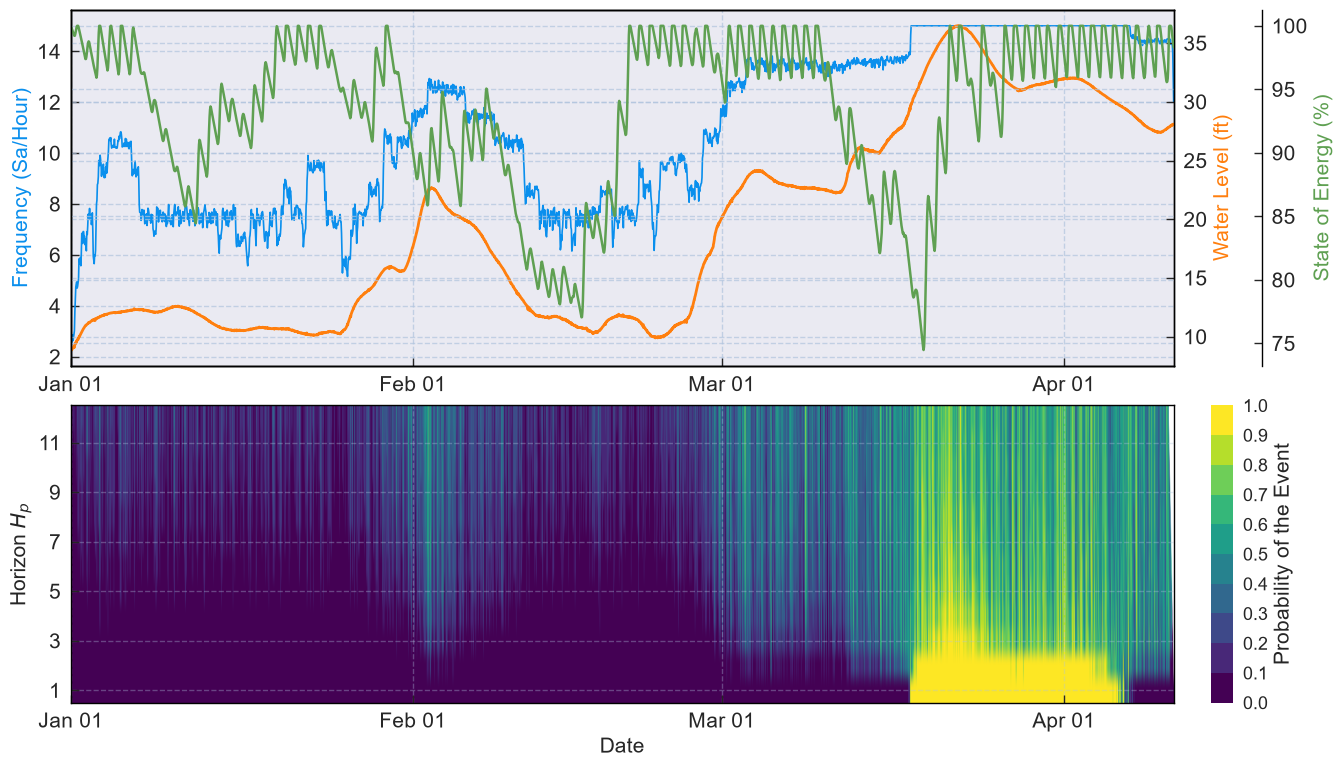

In [101]:
plt.style.use("seaborn-v0_8")
fontsize = 15
linewidth = 2
period = 0
MAX_HORIZON = 12

# 1. Prepare Data
time_index = pd.date_range(start=base_date, periods=len(results), freq="h")
df_zoomed = pd.DataFrame({"Value": results[-period:]}, index=time_index)

mask = (threat_data_raw["Unit"] >= df_zoomed.index[0]) & (threat_data_raw["Unit"] <= df_zoomed.index[-1])
threat_data_filtered = threat_data_raw[mask]
soc_zoomed = pd.DataFrame(system_states)["SoC"][-period:]

probs_zoomed = pd.DataFrame(system_states)["event_probability"][-period:]
padded_probs = [
    np.pad(
        np.array(vec),
        (0, MAX_HORIZON - len(vec)),
        mode="constant",
        constant_values=np.nan,
    )
    if len(vec) < MAX_HORIZON
    else np.array(vec)[:MAX_HORIZON]
    for vec in probs_zoomed.values
]
prob_matrix = np.vstack(padded_probs)

# 2. Build GridSpec (Col 0: Plots, Col 1: Spacer for SoE Spine, Col 2: Colorbar)
fig = plt.figure(figsize=(15, 9))
gs = GridSpec(
    2,
    3,
    width_ratios=[1, 0.0, 0.02],
    height_ratios=[1.2, 1],
    wspace=0.05,
    hspace=0.12,
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)  # Strict X-axis sharing
cax = fig.add_subplot(gs[1, 2])  # Dedicated colorbar axis

# ==============================================================================
# SUBPLOT 1: System States
# ==============================================================================
ax1.plot(
    df_zoomed.index,
    df_zoomed["Value"],
    linewidth=1.2,
    color="#0a8fed",
    label="Frequency",
)

ax1_level = ax1.twinx()
ax1_level.plot(
    threat_data_filtered["Unit"],
    threat_data_filtered["Instantaneous Stream Level (ft)"],
    linewidth=linewidth,
    color="#ff7f0e",
    label="Stream Level",
)

ax1_soc = ax1.twinx()
ax1_soc.plot(df_zoomed.index, soc_zoomed, color="#5fa052", linewidth=1.8, label="SoE")
ax1_soc.spines["right"].set_position(("axes", 1.08))

ax1.set_ylabel("Frequency (Sa/Hour)", fontsize=fontsize, color="#0a8fed")
ax1_level.set_ylabel("Water Level (ft)", fontsize=fontsize, color="#ff7f0e")
ax1_soc.set_ylabel("State of Energy (%)", color="#5fa052", fontsize=fontsize)

for ax in [ax1, ax1_level, ax1_soc]:
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1)
        spine.set_color("black")
    ax.tick_params(
        axis="both", which="both", direction="in", length=6, labelsize=fontsize
    )
    ax.grid(True, linestyle="--", alpha=0.7, color="#b0c4de")

# ==============================================================================
# SUBPLOT 2: Horizon Probability Heatmap P(D)
# ==============================================================================
dates_num = mdates.date2num(df_zoomed.index)
dx = dates_num[1] - dates_num[0] if len(dates_num) > 1 else 1.0 / 24.0
half_dx = dx / 2.0  # Half-pixel offset for exact alignment

bounds = np.linspace(0, 1, 11)
n_bins = len(bounds) - 1

cmap = plt.get_cmap("viridis", n_bins).copy()
cmap.set_bad(color="white")
norm = mcolors.BoundaryNorm(bounds, cmap.N)
# norm = mcolors.Normalize(vmin=0, vmax=1)

# Extent incorporates half_dx padding on edges to align exact pixel bins
im = ax2.imshow(
    prob_matrix.T,
    aspect="auto",
    origin="lower",
    cmap=cmap,
    norm=norm,
    extent=[dates_num[0] - half_dx, dates_num[-1] + half_dx, 0.5, 12.5],
)

ax2.set_ylabel(r"Horizon $H_p$", fontsize=fontsize)
ax2.set_xlabel("Date", fontsize=fontsize)
ax2.set_yticks(range(1, 13, 2))

for spine in ax2.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)
    spine.set_color("black")
ax2.tick_params(axis="both", which="both", direction="in", length=6, labelsize=fontsize)
ax2.grid(True, linestyle="--", alpha=0.35, color="#b0c4de")

# Colorbar strictly in cax (prevents ax2 shrinking)
cbar = fig.colorbar(im, cax=cax, ticks=np.linspace(0, 1, 11), pad=-2)
cbar.set_label("Probability of the Event", fontsize=fontsize)
cbar.ax.tick_params(labelsize=fontsize - 2)

# X-Axis formatting
ax2.set_xlim(dates_num[0], dates_num[-1])
# ax2.xaxis_date()
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=1))

# plt.savefig(f'./outputs/meeting friday/heatmap_baseline_f8_02131000.png', dpi=150, bbox_inches='tight')
plt.show()